# Routing method comparison: all metrics

This notebook calls `return_ops_all_methods` once for each graph parameter. Each call collects SWAP counts after routing, two-qubit gate counts and circuit depth after optimization, and transpilation time for both paths.

## Imports and backend

In [11]:
import importlib
import helper_functions as _helper_functions
importlib.reload(_helper_functions)
return_ops_all_methods = _helper_functions.return_ops_all_methods
return_times_all_methods = _helper_functions.return_times_all_methods
plot_metric_results = _helper_functions.plot_metric_results
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
from IPython.display import display
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

backend = FakeMarrakesh()


## Experiment configuration

In [12]:
k_list = [4]
average_over = 5
reps = 1
opt_level = 1

# Keep the graph sizes and parameter ranges comparable to comparison_plots_final.ipynb.
nodes_reg = list(range(10, 151, 2))
params_reg = list(range(3, 9))
nodes_ba = list(range(6, 151, 2))
params_ba = list(range(2, 5))

## Collect all metrics

The function internally runs both routing paths, so each parameter only needs one call.

In [3]:
# results_reg = {}
# for param in params_reg:
#     results_reg[param] = return_ops_all_methods(
#         backend,
#         graph_type='reg',
#         param=param,
#         average_over=average_over,
#         node_list=nodes_reg,
#         k_list=k_list,
#         reps=reps,
#         opt_level=opt_level,
#         noise_aware=True,
#     )

# results_ba = {}
# for param in params_ba:
#     results_ba[param] = return_ops_all_methods(
#         backend,
#         graph_type='ba',
#         param=param,
#         average_over=average_over,
#         node_list=nodes_ba,
#         k_list=k_list,
#         reps=reps,
#         opt_level=opt_level,
#         noise_aware=True,
#     )

# Timing is kept separate from circuit-quality metrics so every stage can be compared fairly.
times_reg = {}
for param in params_reg:
    times_reg[param] = return_times_all_methods(
        backend,
        graph_type='reg',
        param=param,
        average_over=average_over,
        node_list=nodes_reg,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )

times_ba = {}
for param in params_ba:
    times_ba[param] = return_times_all_methods(
        backend,
        graph_type='ba',
        param=param,
        average_over=average_over,
        node_list=nodes_ba,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )

In [13]:
quality_plots = [
    ('swaps', 'SWAP count', 'SWAPs'),
    ('two_qubit_gates', 'Two-qubit gate count', 'Two-qubit gates'),
    ('circuit_depth', 'Optimized circuit depth', 'Circuit depth'),
]
time_plots = [
    ('mapping_time', 'Mapping time', 'Time (seconds)'),
    # ('circuit_generation_time', 'Initial circuit generation time', 'Time (seconds)'),
    ('routing_time', 'Routing time', 'Time (seconds)'),
    ('optimization_time', 'Final optimization time', 'Time (seconds)'),
    ('total_compilation_time', 'Total compilation time', 'Time (seconds)'),
]

# RR Time

Random regular graphs: Mapping time


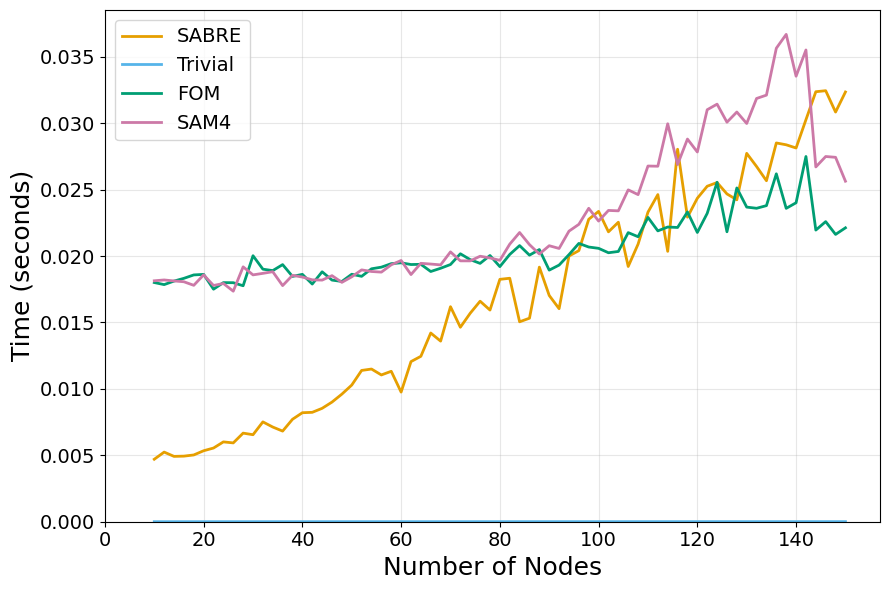

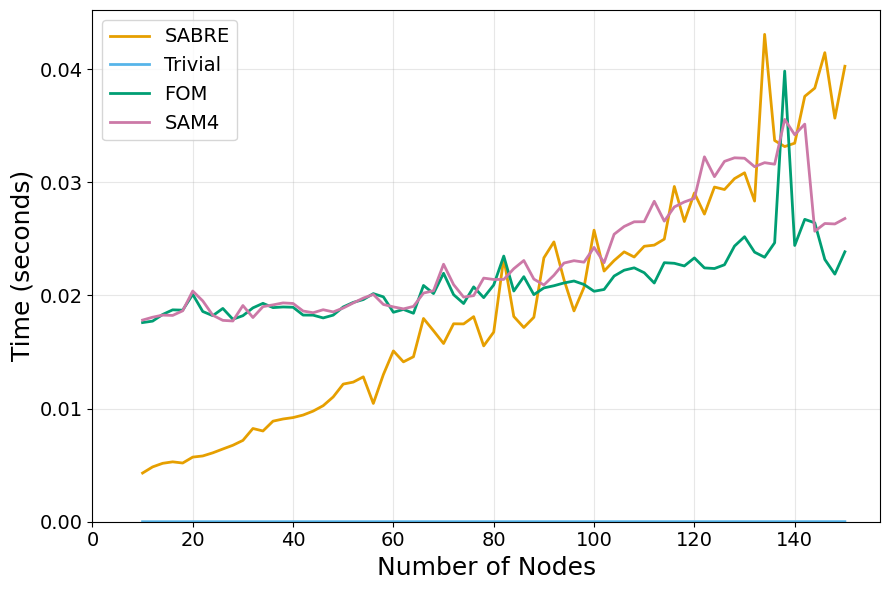

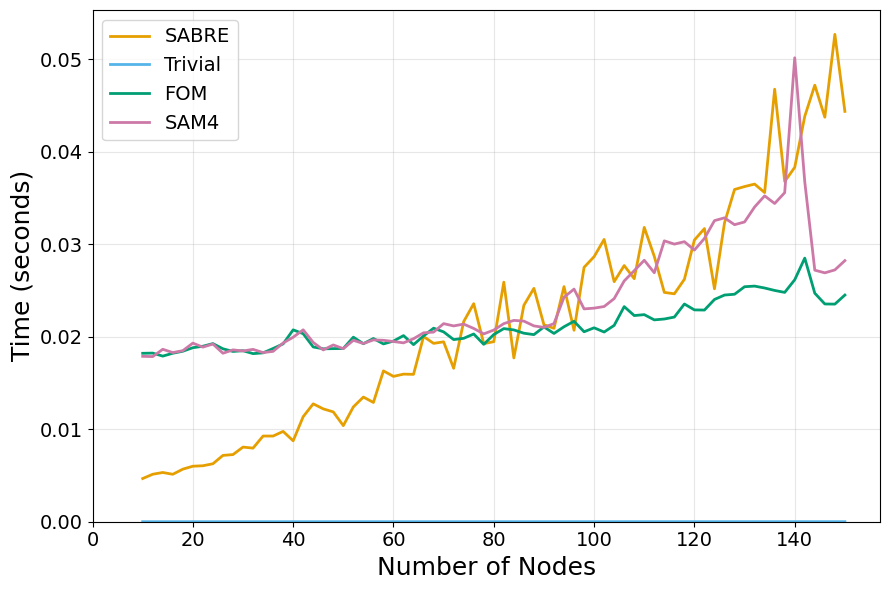

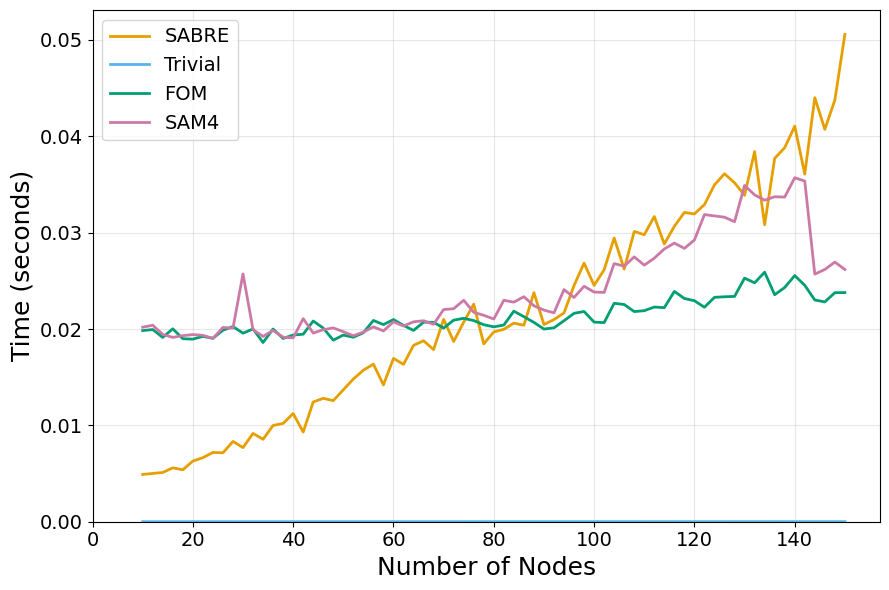

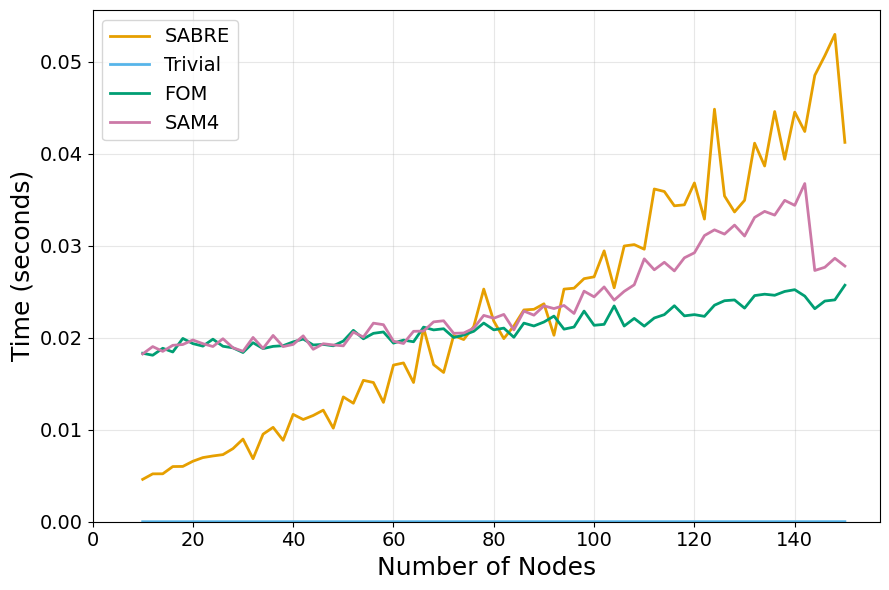

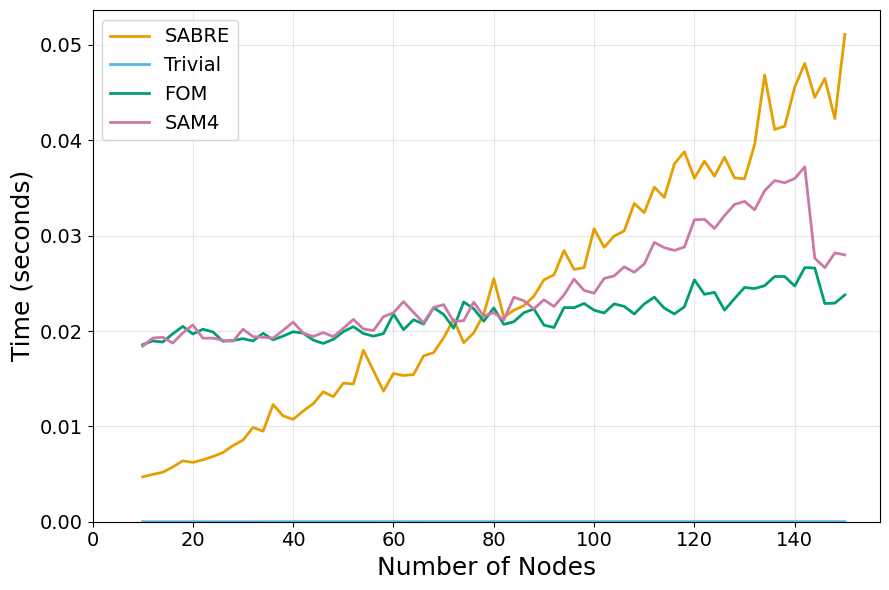

Random regular graphs: Routing time


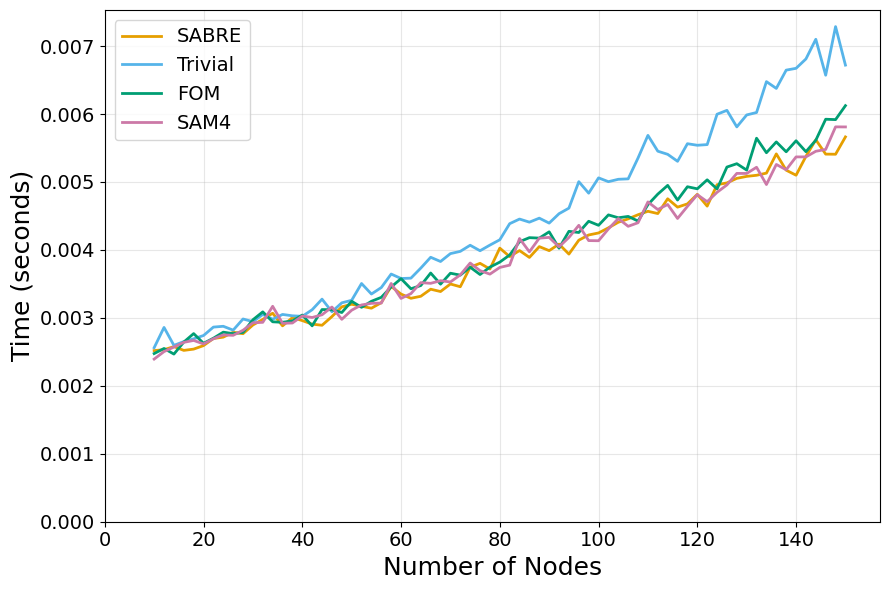

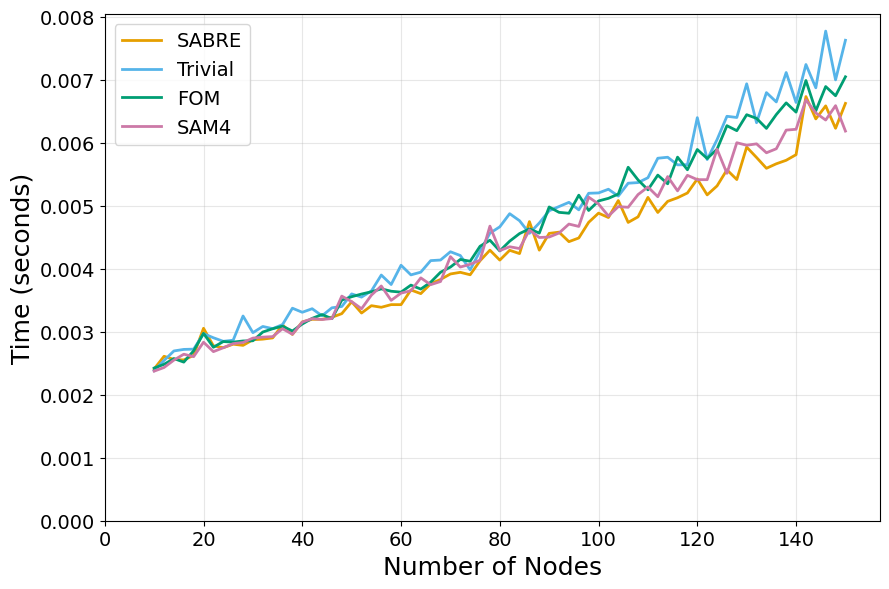

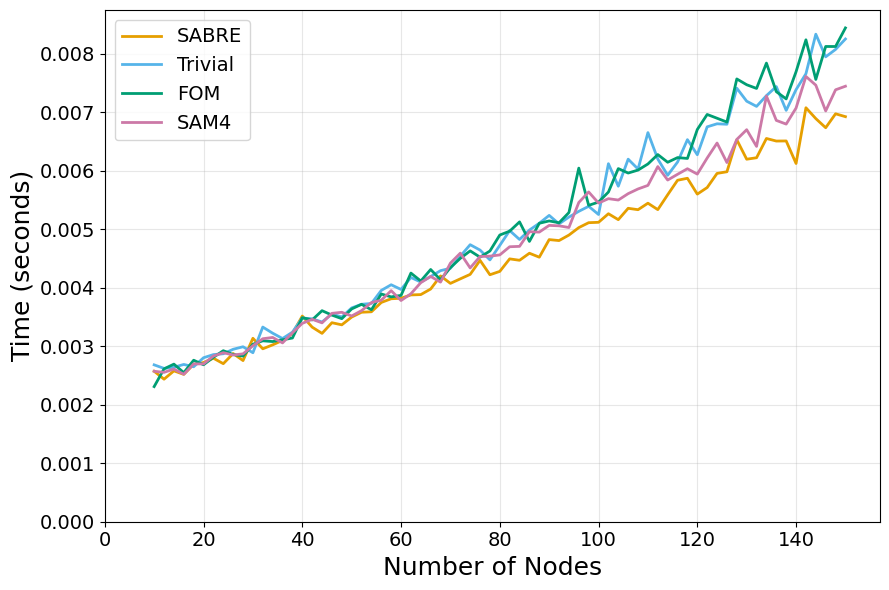

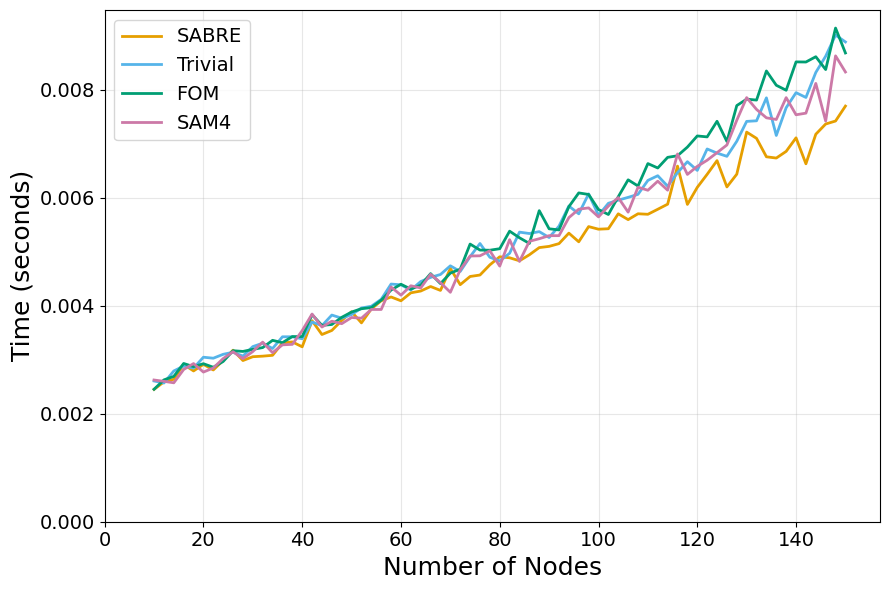

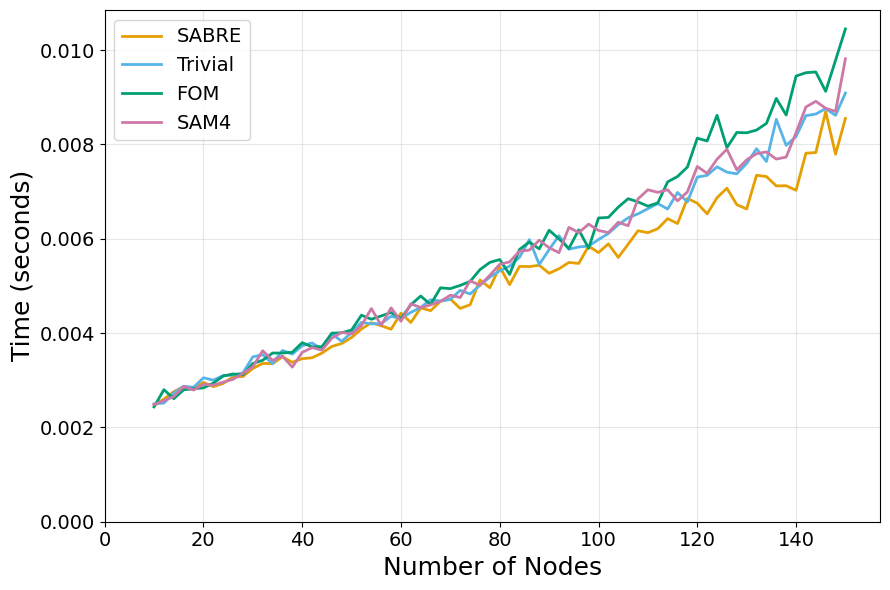

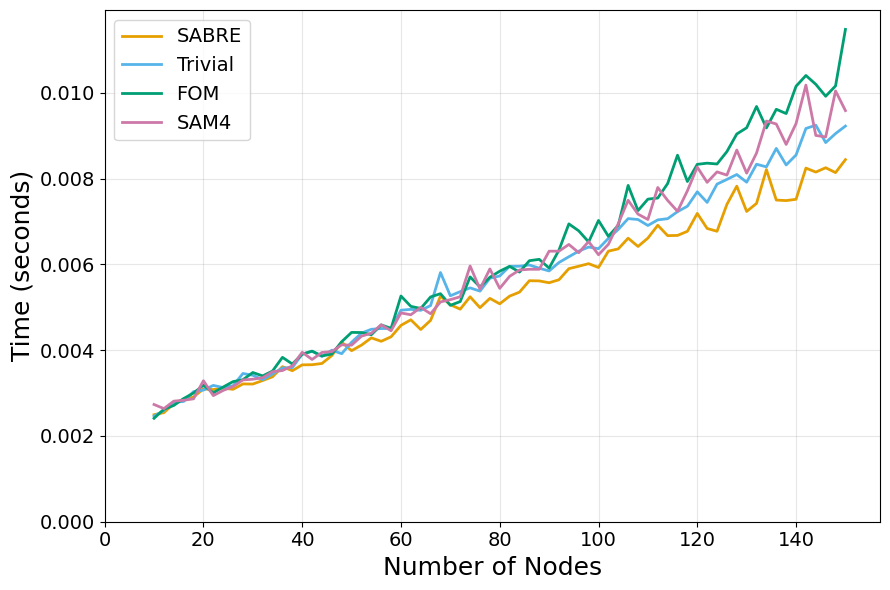

Random regular graphs: Final optimization time


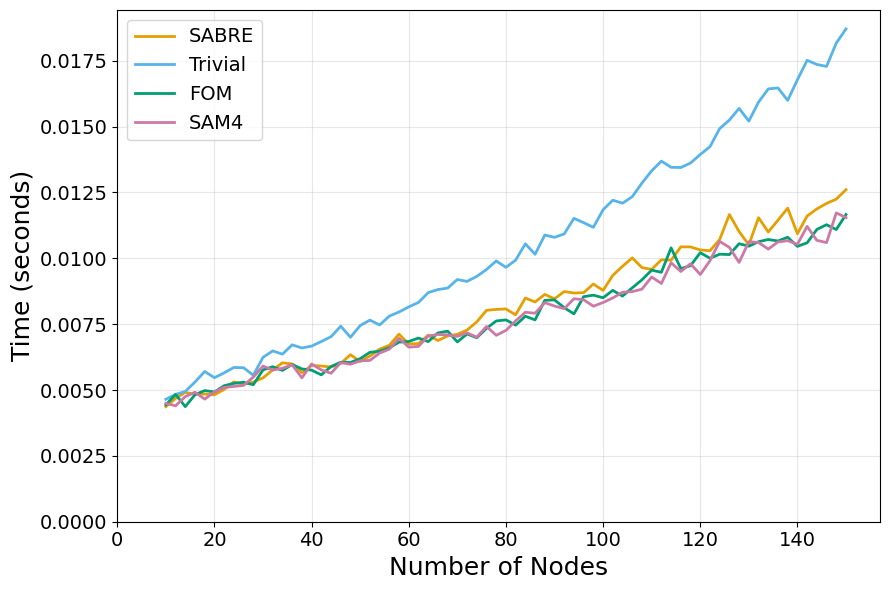

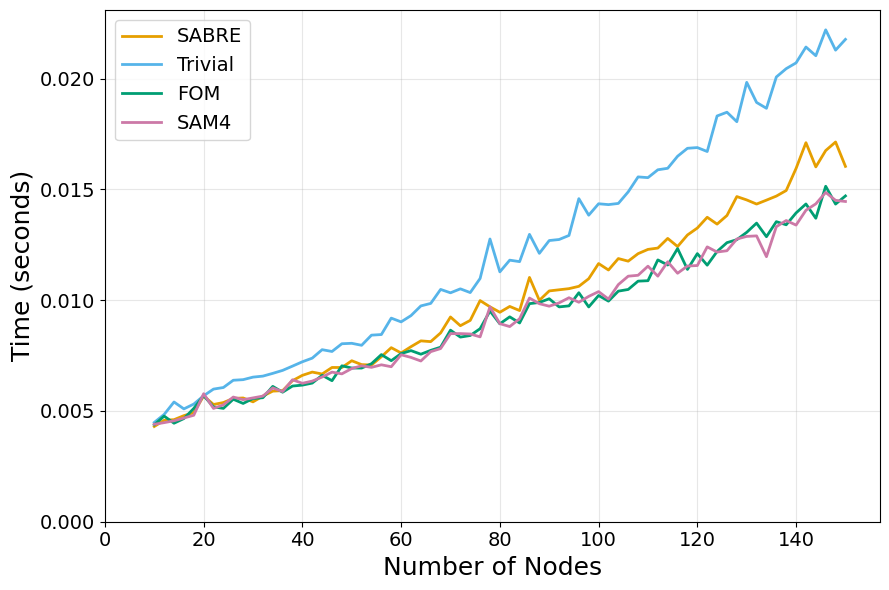

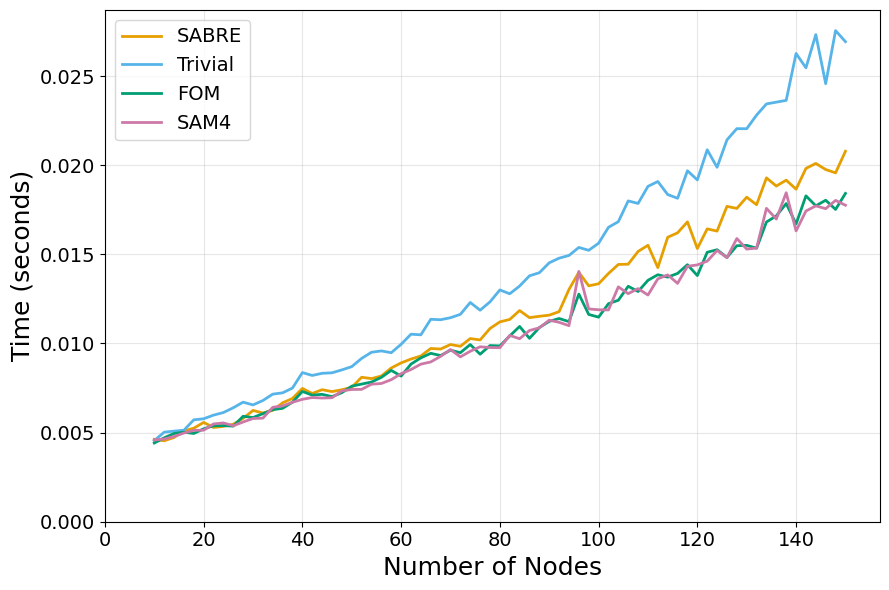

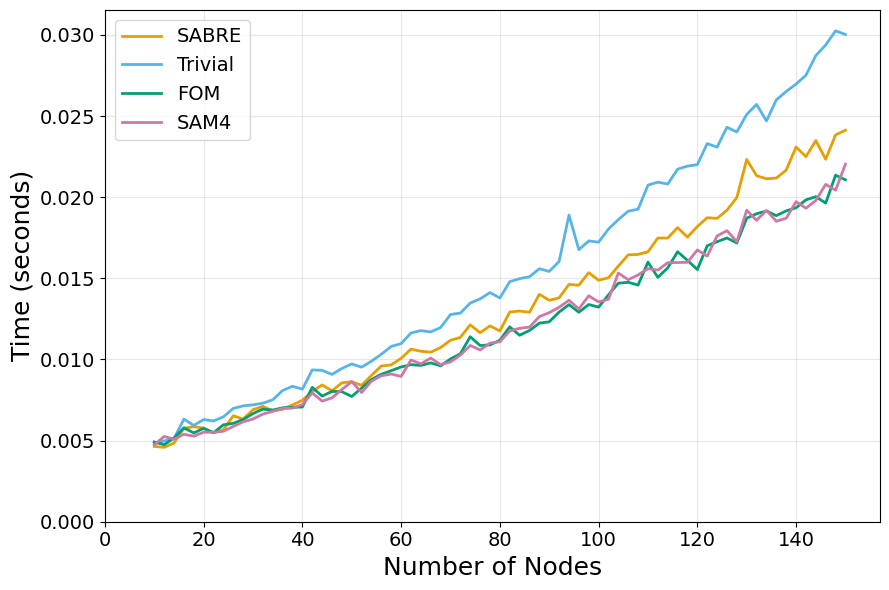

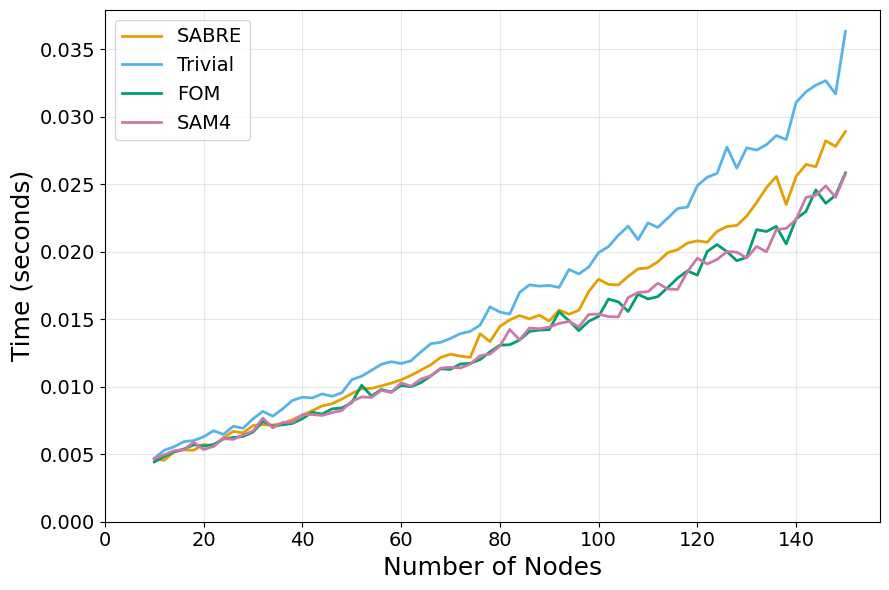

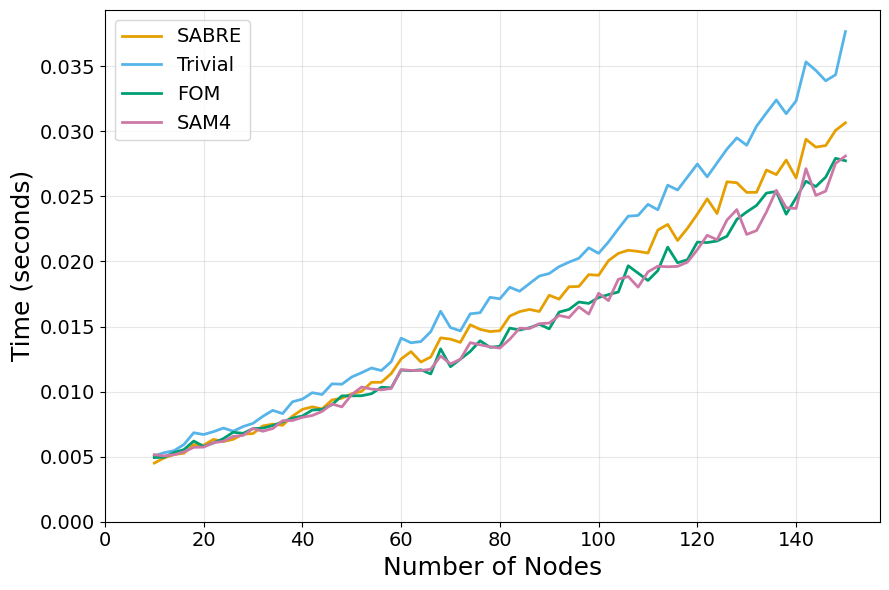

Random regular graphs: Total compilation time


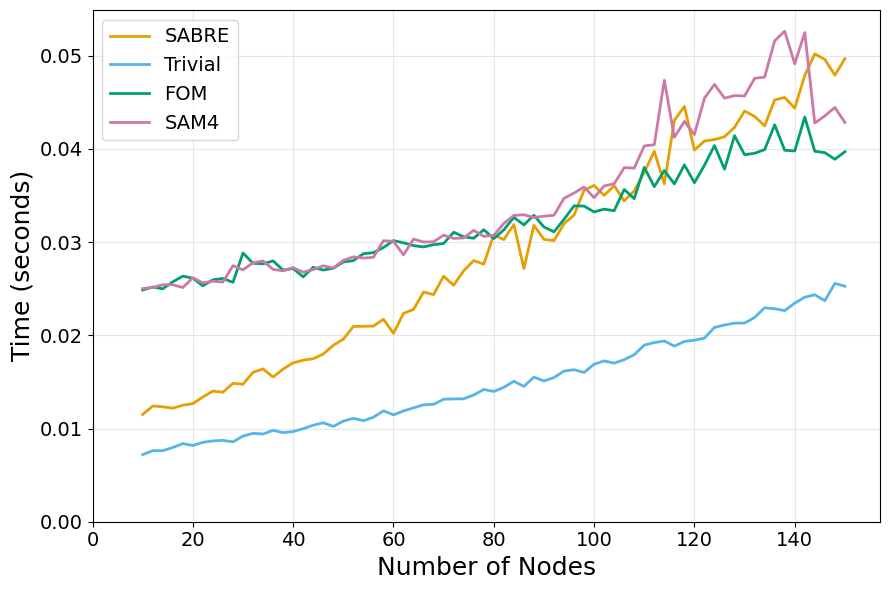

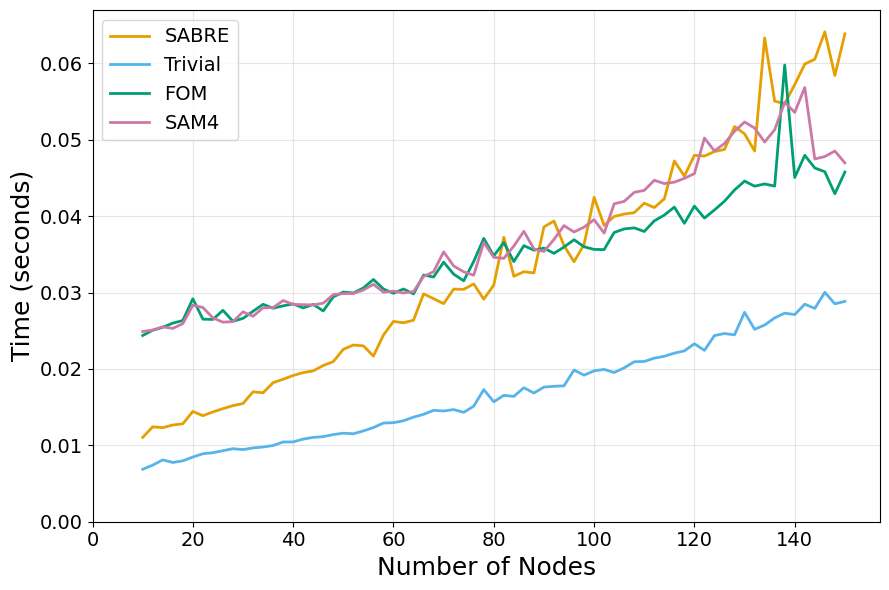

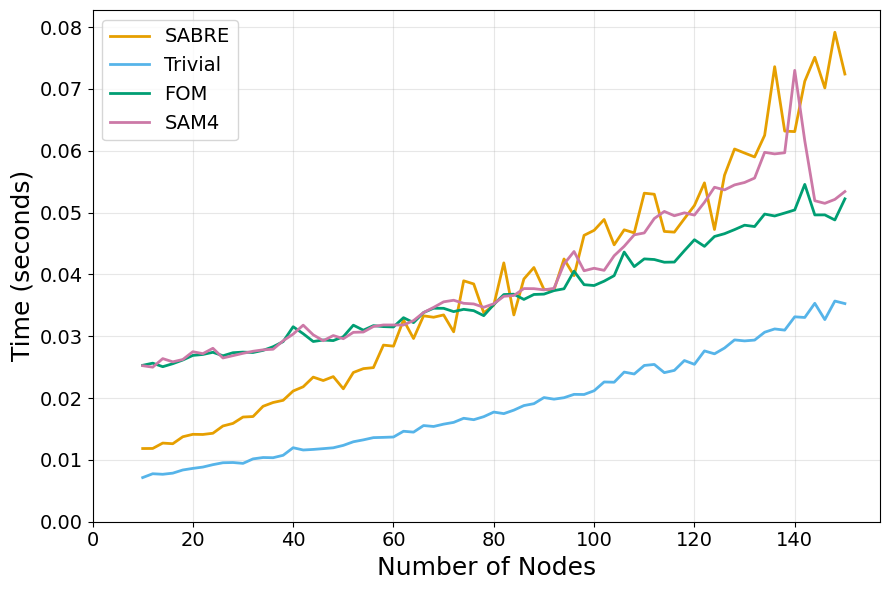

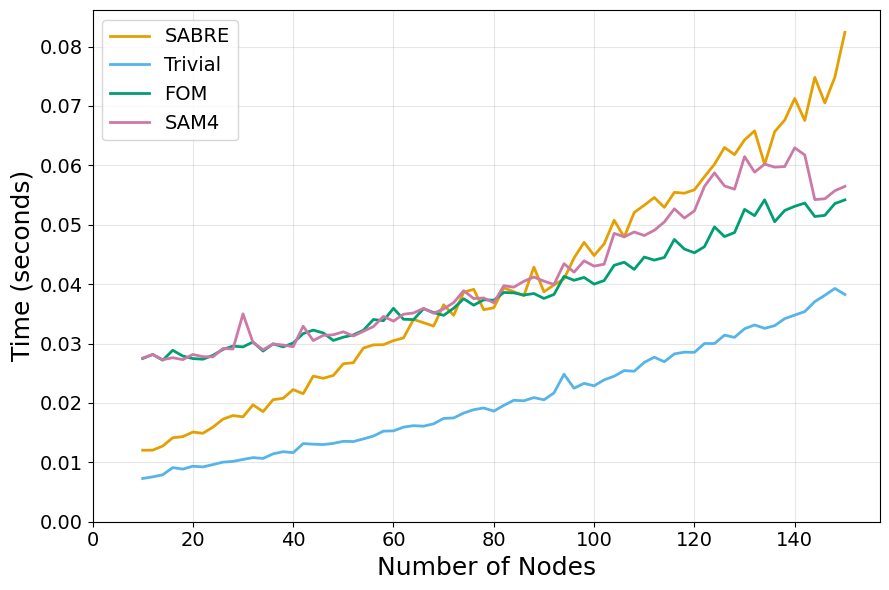

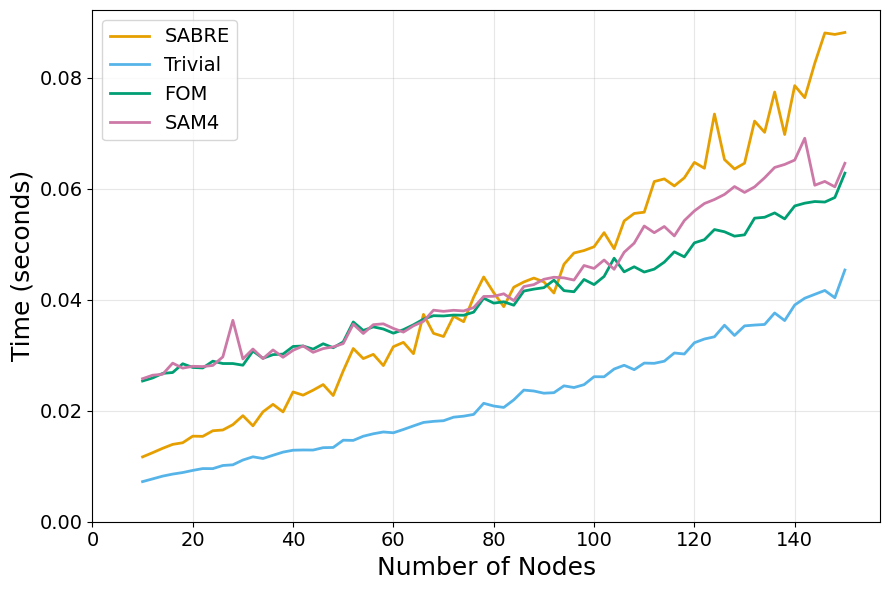

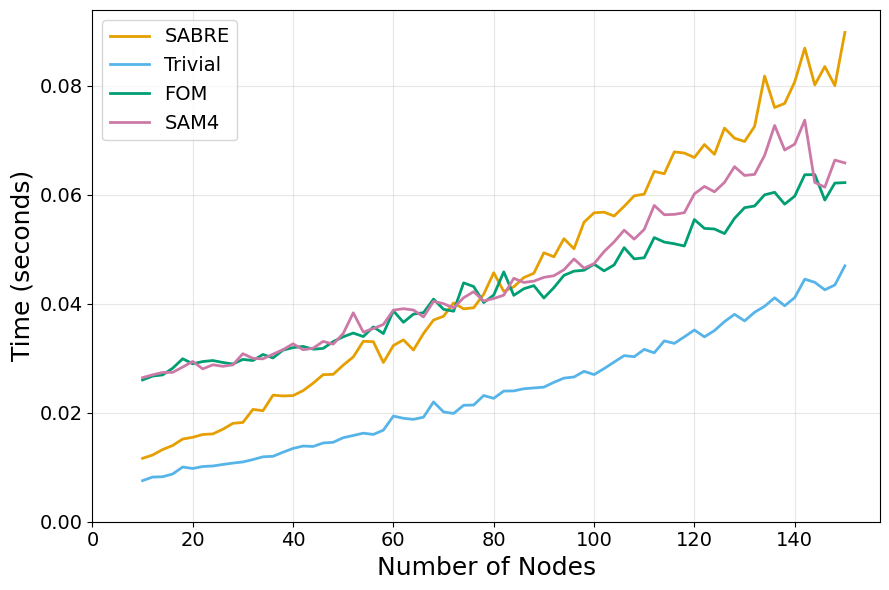

In [5]:

for metric, title, ylabel in time_plots:
    print(f'Random regular graphs: {title}')
    plot_metric_results(
        times_reg, nodes_reg, k_list, params_reg, metric=metric,
        title_prefix=f'Random regular graphs: {title}', ylabel=ylabel, fill_between=False, plot='median'
    )



# BA Time

Barabasi-Albert graphs: Mapping time


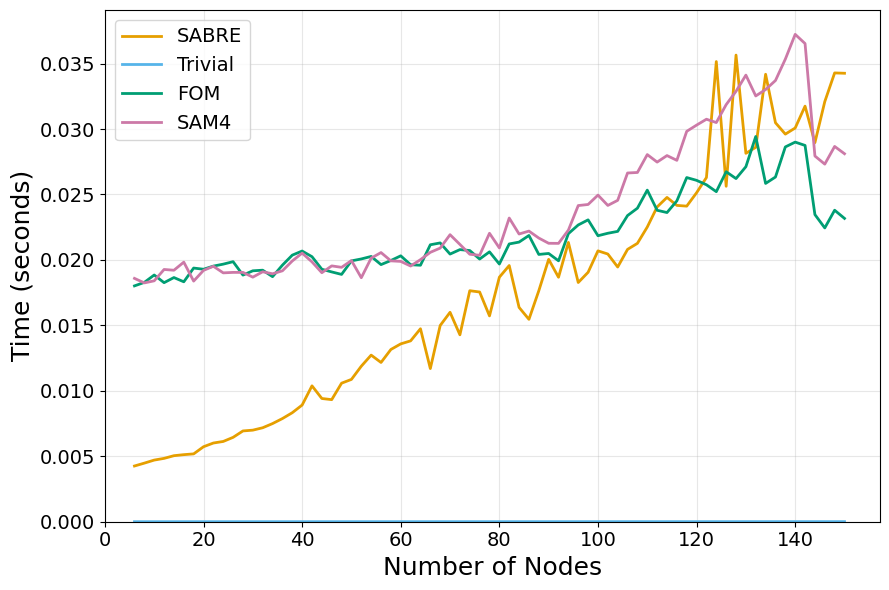

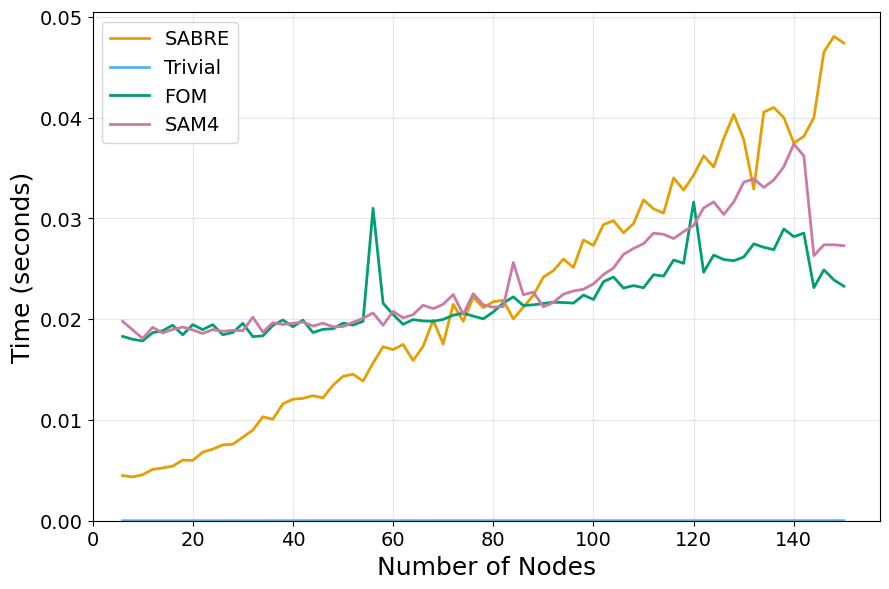

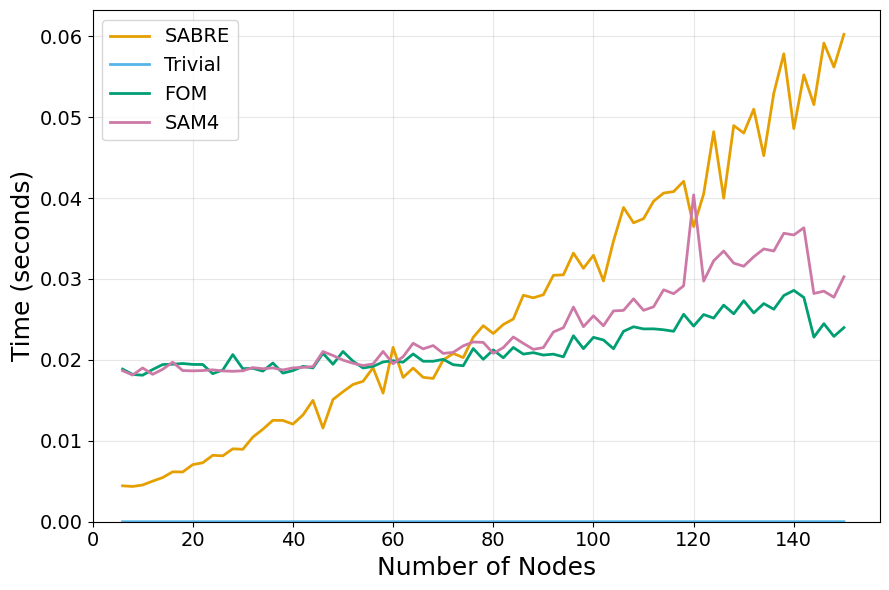

Barabasi-Albert graphs: Routing time


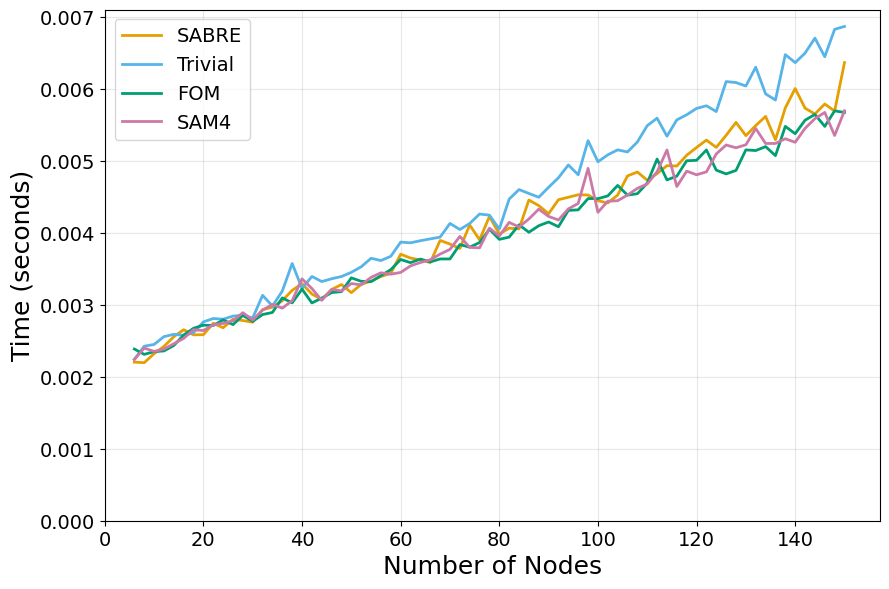

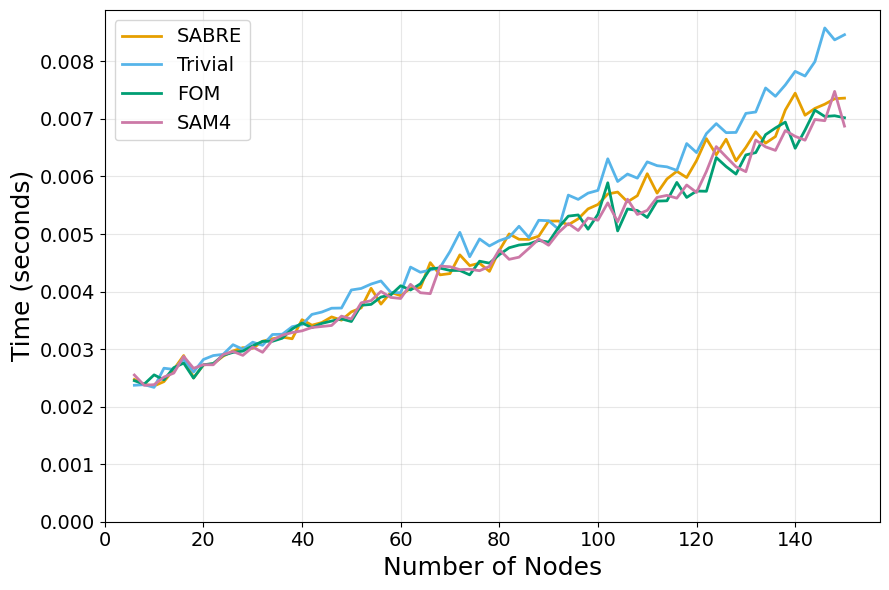

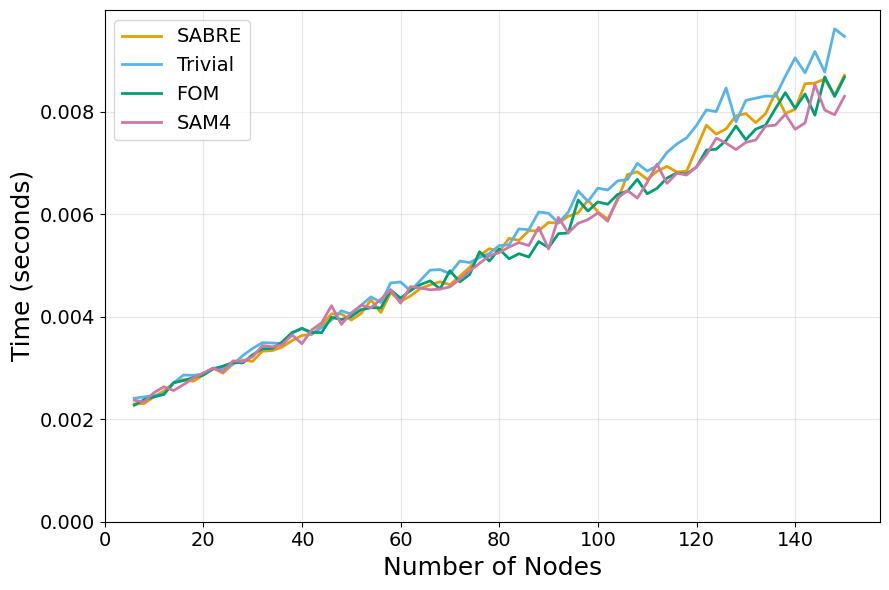

Barabasi-Albert graphs: Final optimization time


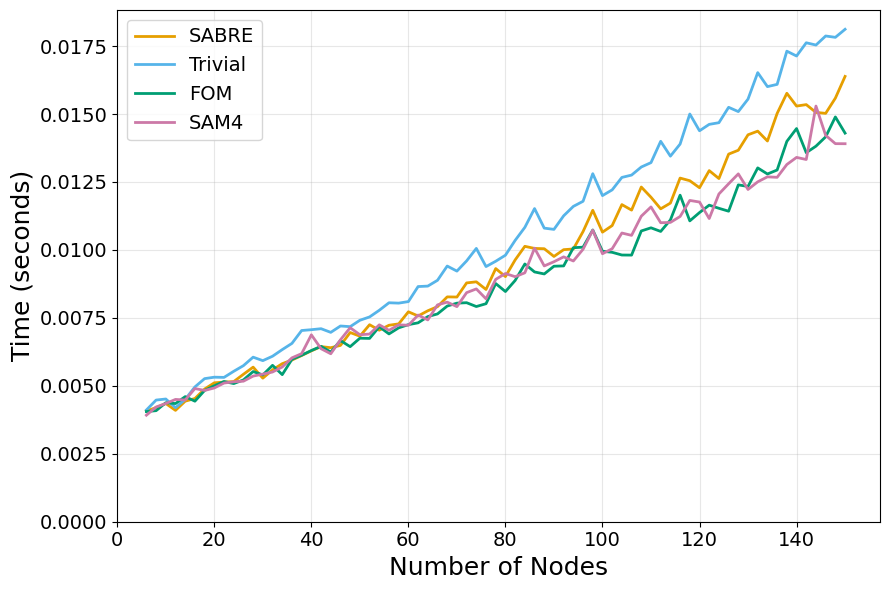

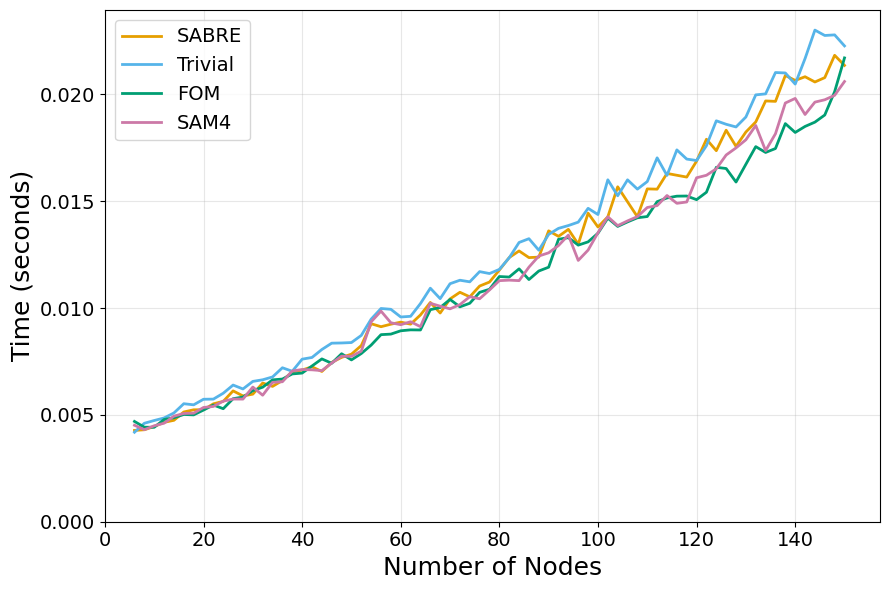

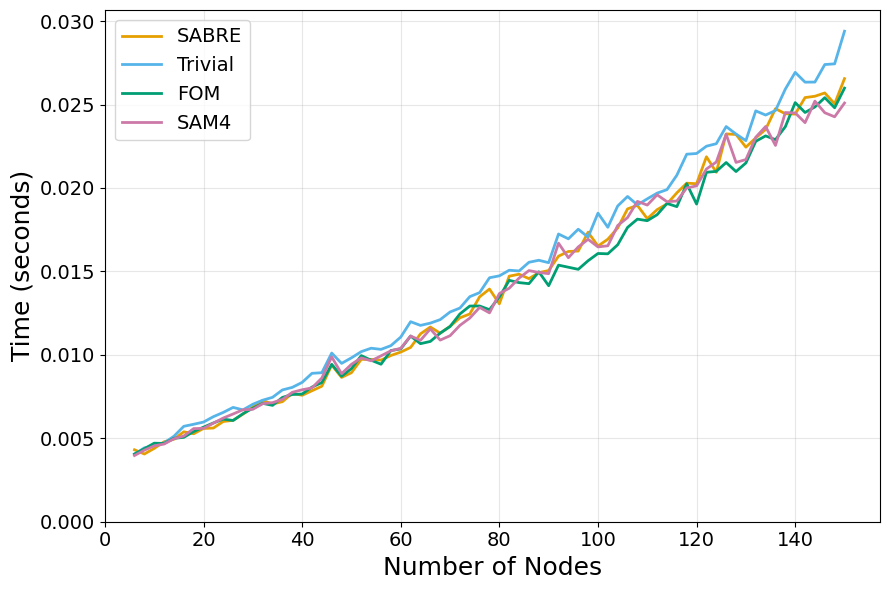

Barabasi-Albert graphs: Total compilation time


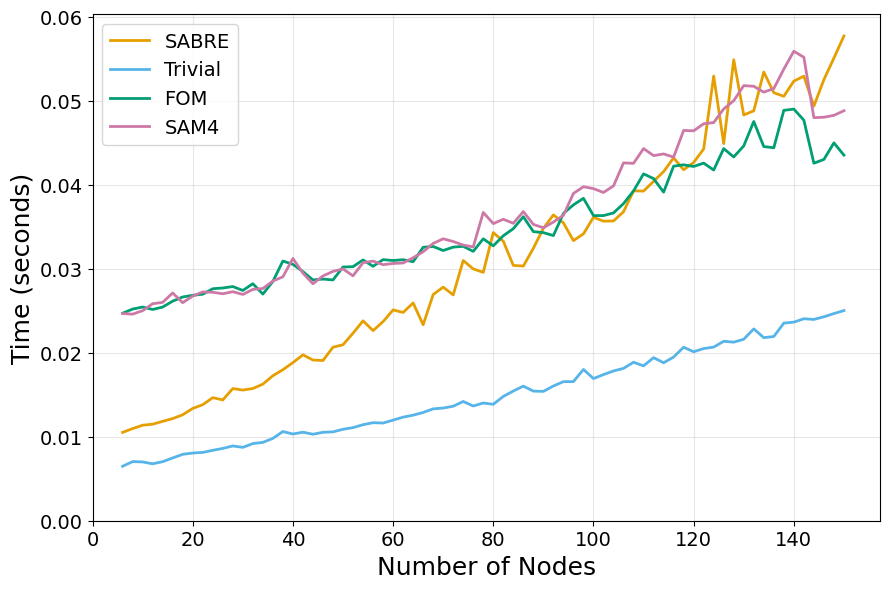

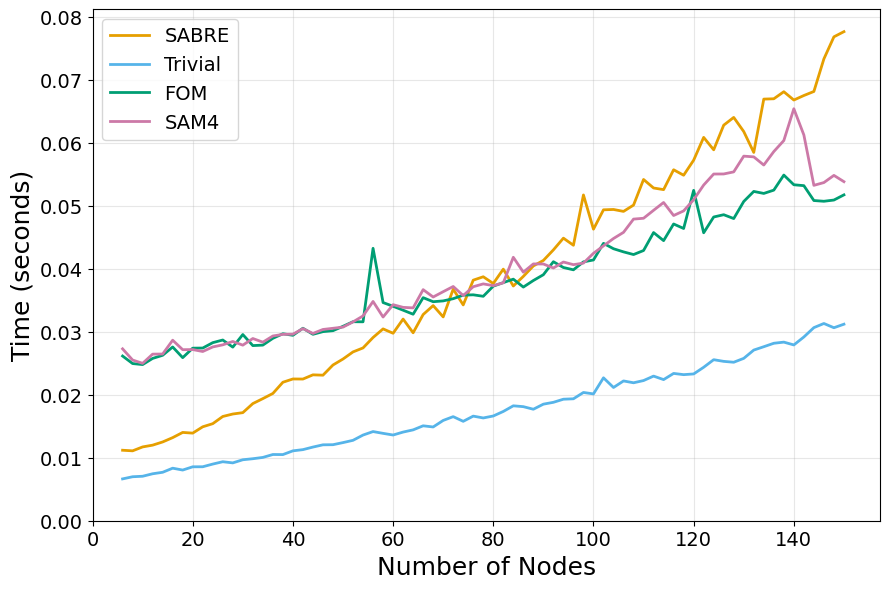

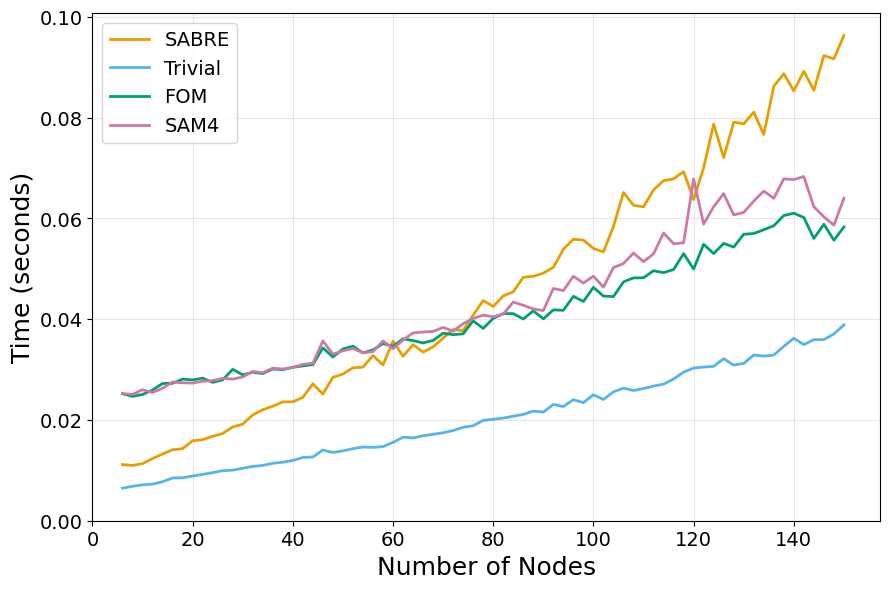

In [6]:
for metric, title, ylabel in time_plots:
    print(f'Barabasi-Albert graphs: {title}')
    plot_metric_results(
        times_ba, nodes_ba, k_list, params_ba, metric=metric,
        title_prefix=f'Barabasi-Albert graphs: {title}', ylabel=ylabel, fill_between=False, plot='median'
    )

## Mapping versus total compilation time

Solid lines show mapping time and dashed lines show total compilation time (mapping + routing + optimization). Values are means after removing one smallest and one largest timing sample per node and method.


In [ ]:
k_list = [4]
average_over = 5
reps = 1
opt_level = 1

# Keep the graph sizes and parameter ranges comparable to comparison_plots_final.ipynb.
nodes_reg = list(range(10, 151, 2))
params_reg = list(range(3, 9))
nodes_ba = list(range(6, 151, 2))
params_ba = list(range(2, 5))

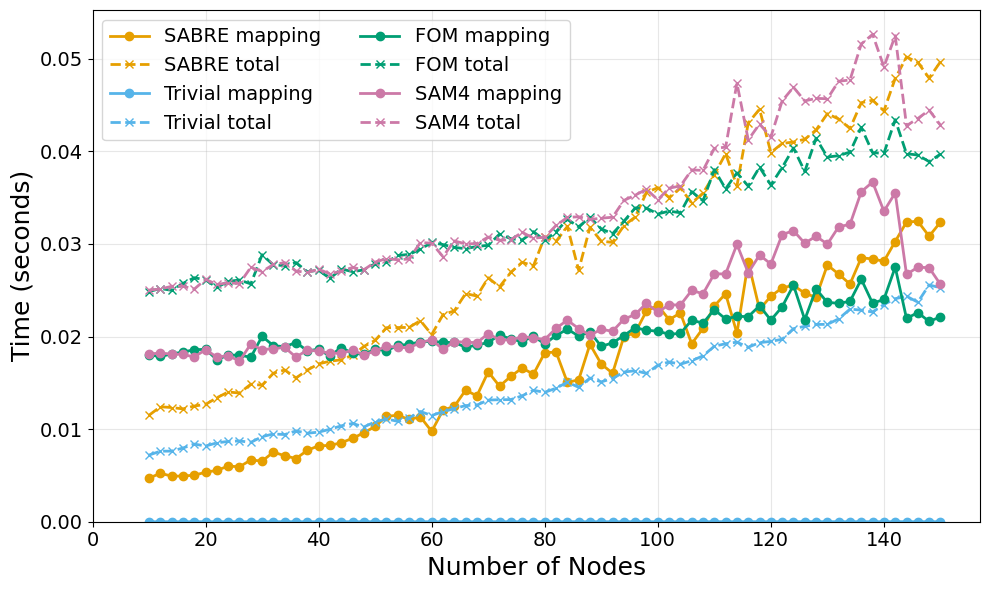

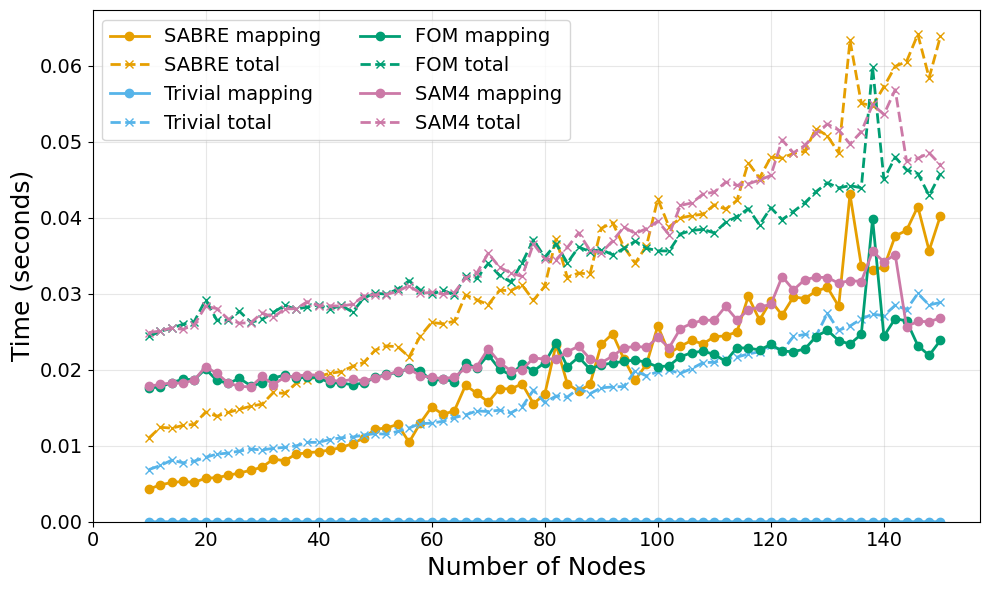

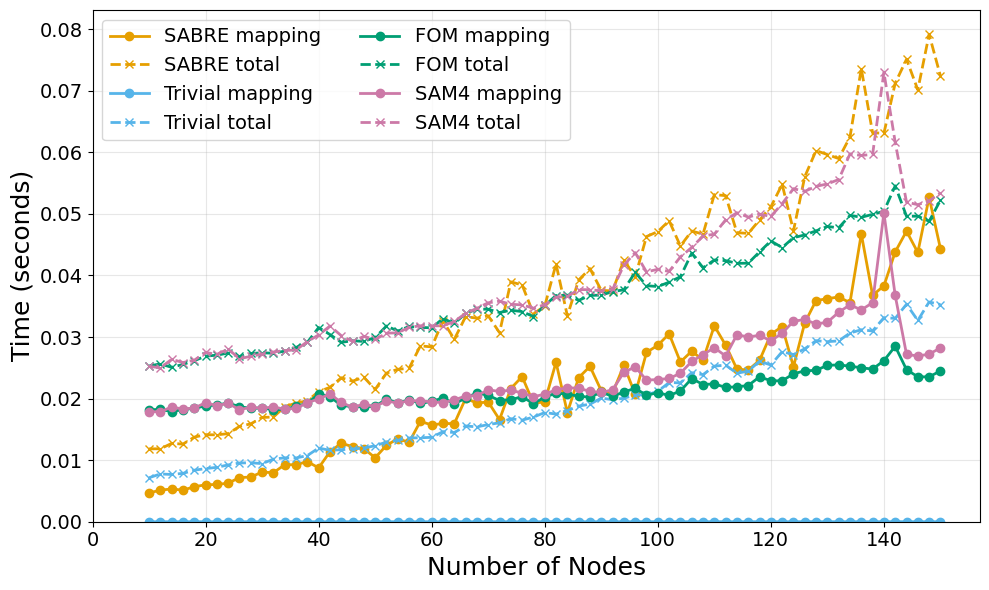

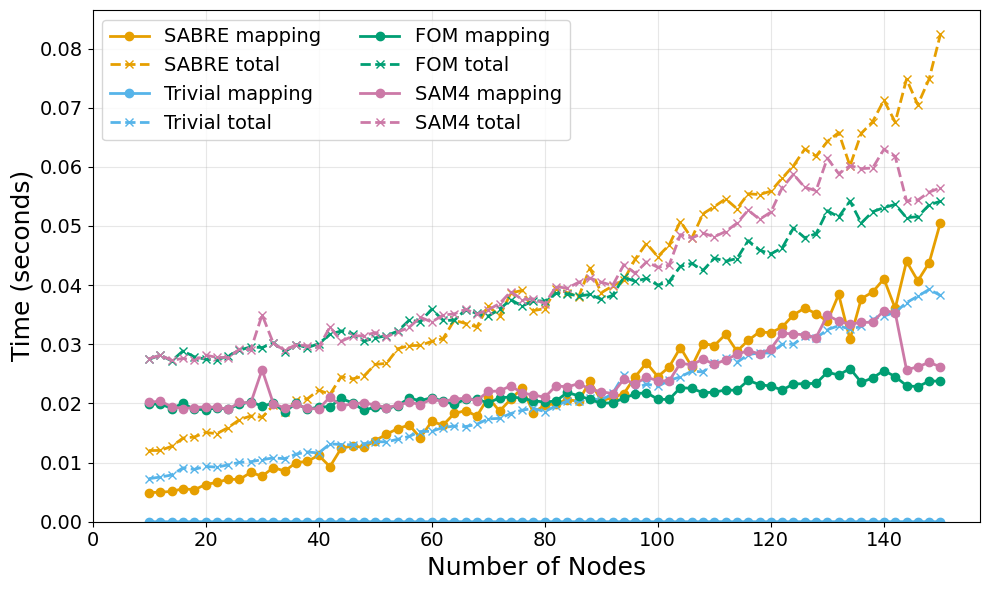

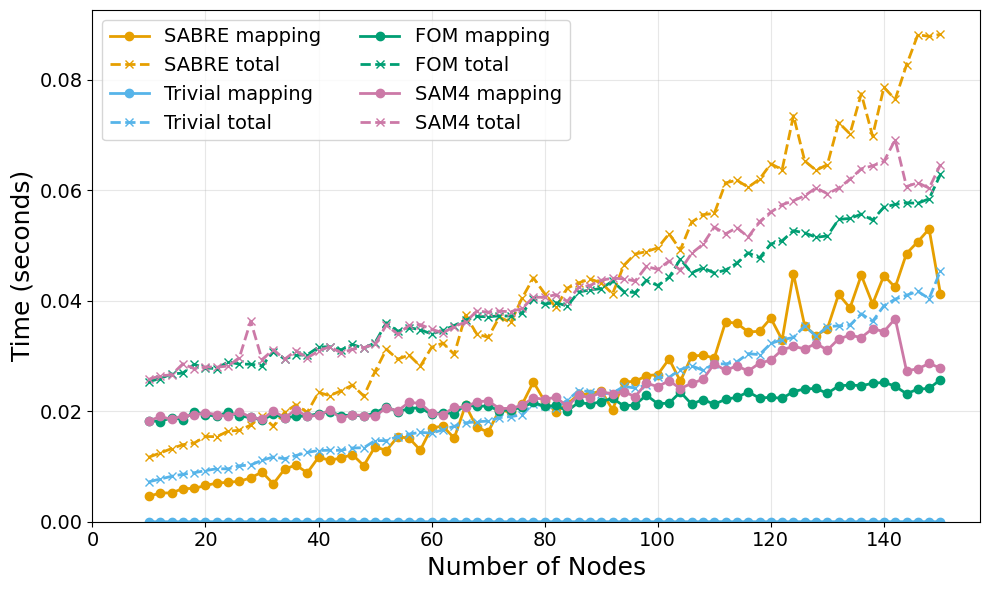

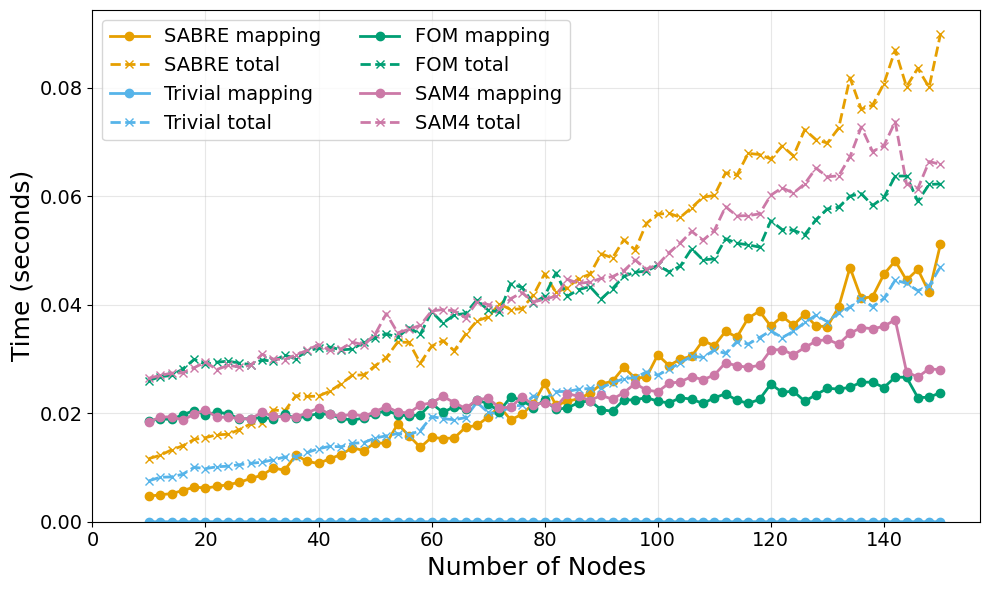

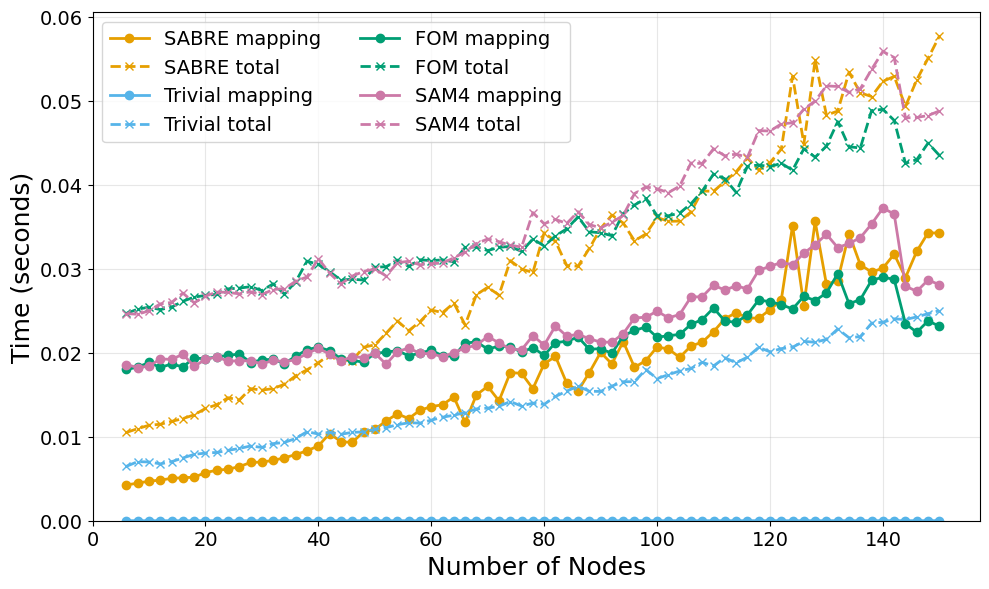

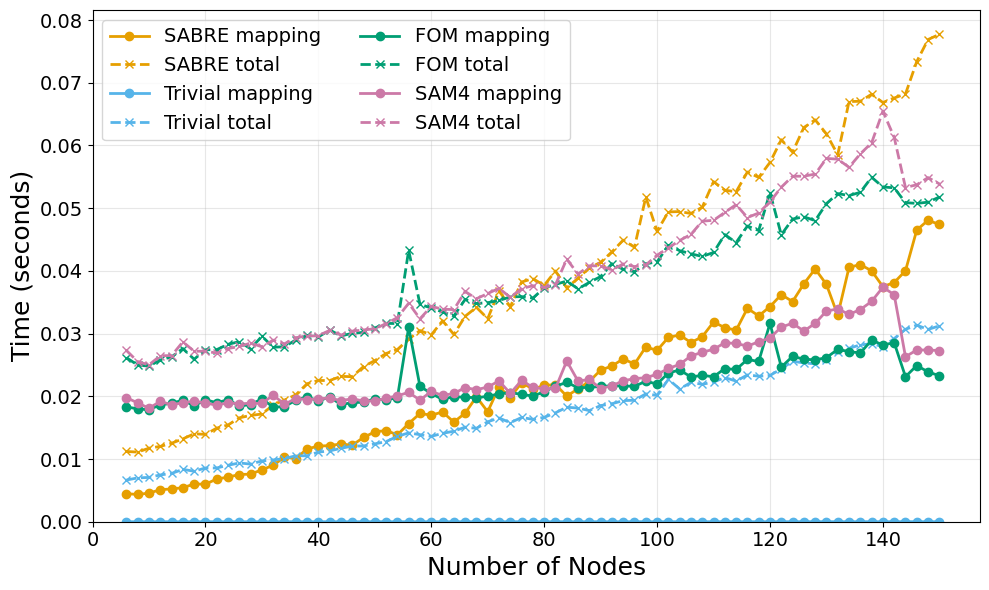

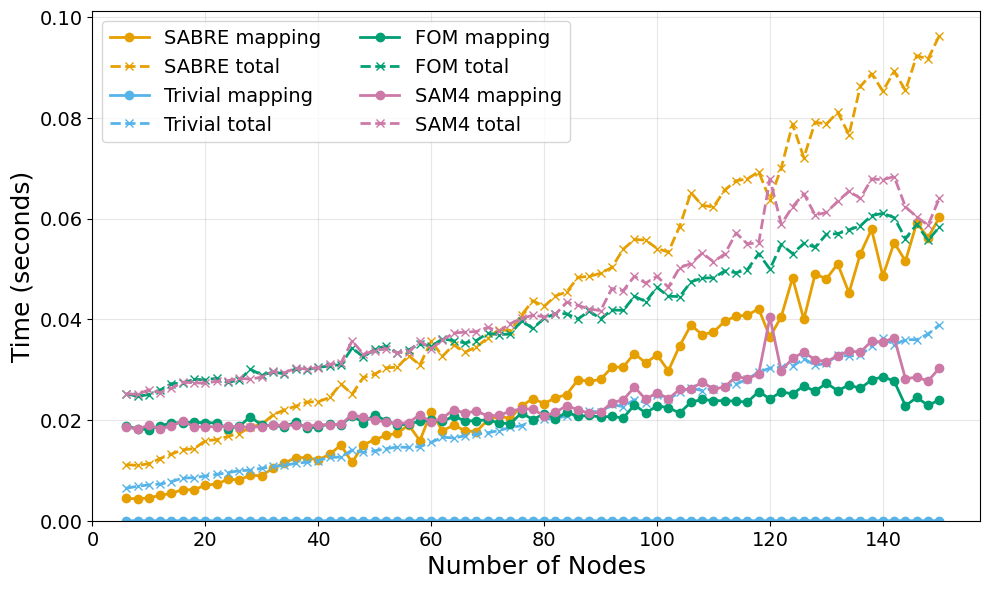

In [10]:
import matplotlib.pyplot as plt
import numpy as np

comparison_method_colors = {
    'SABRE': '#E69F00',
    'Trivial': '#56B4E9',
    'FOM': '#009E73',
    'SAM2': '#0072B2',
    'SAM3': '#D55E00',
    'SAM4': '#CC79A7',
    'SAM5': '#F0E442',
}


def plot_mapping_and_total_time(results, node_list, params, graph_label):
    """Overlay trimmed means for mapping and total compilation time."""
    for param in params:
        if 'total_compilation_time' not in results[param]:
            raise KeyError(
                "Missing total_compilation_time. Rerun the metric collection cell "
                "after updating helper_functions.py."
            )

        if (
            'trimmed_means' not in results[param]['mapping_time']
            or 'trimmed_means' not in results[param]['total_compilation_time']
        ):
            raise KeyError(
                'Trimmed means are missing. Rerun return_times_all_methods after '
                'updating helper_functions.py.'
            )
        mapping_stats = results[param]['mapping_time']['trimmed_means']
        total_stats = results[param]['total_compilation_time']['trimmed_means']
        methods = list(mapping_stats)
        fig, ax = plt.subplots(figsize=(10, 6))

        for method in methods:
            color = comparison_method_colors.get(method)
            mapping_values = np.asarray(mapping_stats[method])
            total_values = np.asarray(total_stats[method])
            ax.plot(
                node_list, mapping_values,
                color=color, linestyle='-', marker='o', linewidth=2,
                label=f'{method} mapping',
            )
            ax.plot(
                node_list, total_values,
                color=color, linestyle='--', marker='x', linewidth=2,
                label=f'{method} total',
            )

        ax.set_xlabel('Number of Nodes', fontsize=18)
        ax.set_ylabel('Time (seconds)', fontsize=18)
        # ax.set_title(f'{graph_label}: mapping and total compilation time (param = {param})')
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.3)
        ax.legend(ncol=2, fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=14)

        fig.tight_layout()
        plt.show()


plot_mapping_and_total_time(times_reg, nodes_reg, params_reg, 'Random regular graphs')
plot_mapping_and_total_time(times_ba, nodes_ba, params_ba, 'Barab?si?Albert graphs')


## Total compilation time by optimization level

This section measures opt levels 2 and 3 for 3-regular, 5-regular, and Barab?si?Albert (m=3) graphs. Results are cached beside the notebook in `comparison_plots_revision_time_opt2_opt3.json`, with a checkpoint after each graph/optimization-level pair. Older cached results without trimmed means are refreshed.


No opt-level-2/3 timing cache found; collecting and checkpointing results.


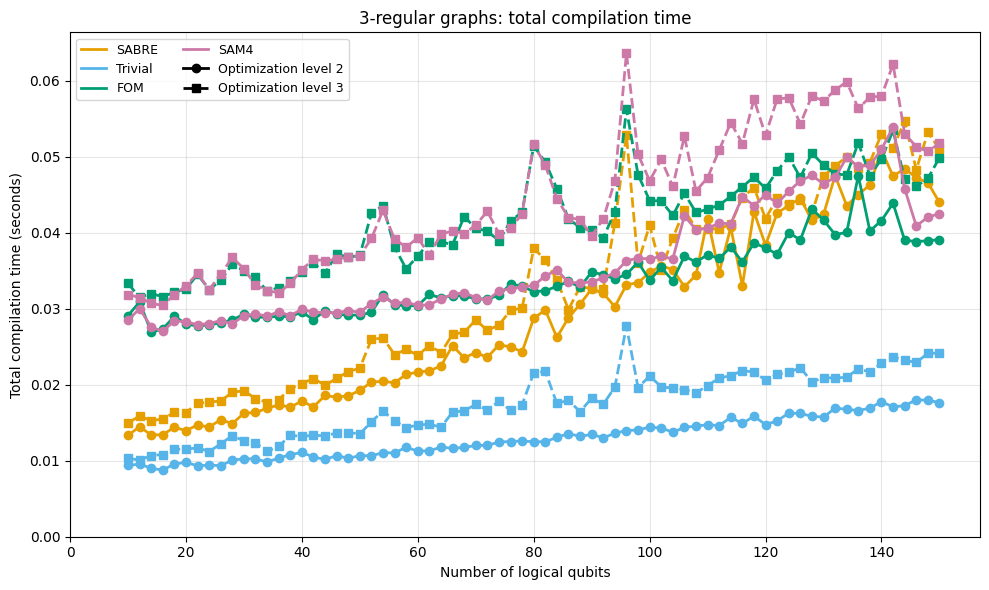

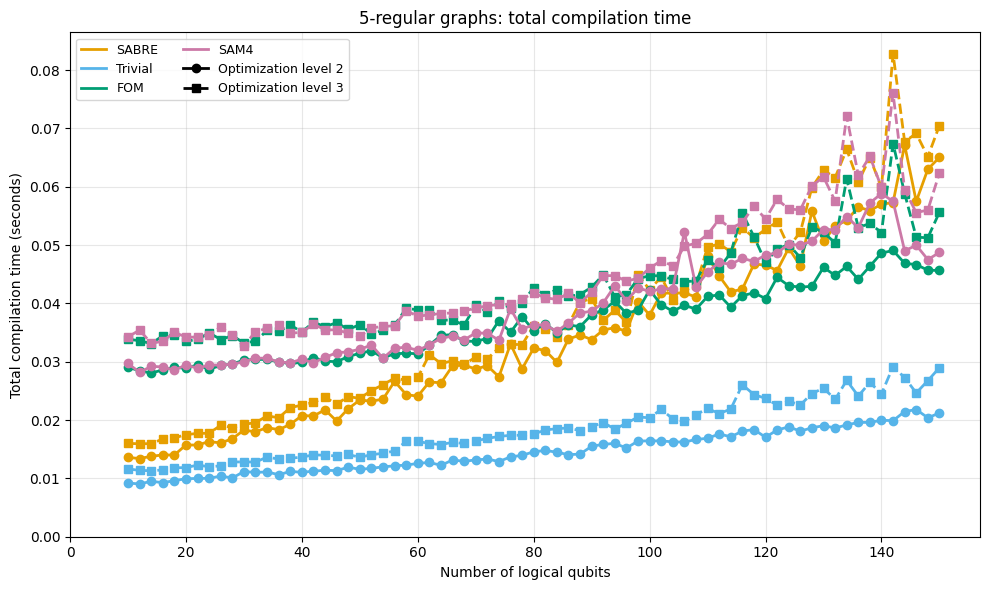

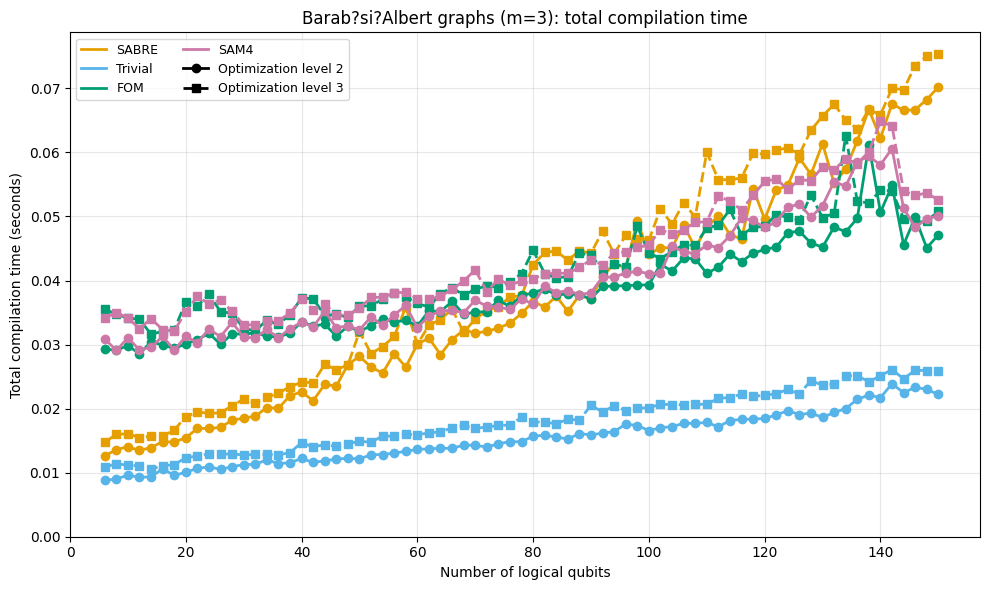

In [ ]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# Save beside helper_functions.py from either the repository root or submissions/.
_time_cache_dir = Path.cwd()
if not (_time_cache_dir / 'helper_functions.py').is_file() and (_time_cache_dir / 'submissions' / 'helper_functions.py').is_file():
    _time_cache_dir = _time_cache_dir / 'submissions'
OPT_LEVEL_RESULTS_FILE = _time_cache_dir / 'comparison_plots_revision_time_opt2_opt3.json'
RECOMPUTE_OPT_LEVEL_RESULTS = False
OPT_LEVELS_TO_COMPARE = [2, 3]

opt_level_cases = {
    'reg_d3': ('reg', 3, nodes_reg, '3-regular graphs'),
    'reg_d5': ('reg', 5, nodes_reg, '5-regular graphs'),
    'ba_m3': ('ba', 3, nodes_ba, 'Barab?si?Albert graphs (m=3)'),
}
opt_level_config = {
    'opt_levels': OPT_LEVELS_TO_COMPARE,
    'average_over': int(average_over),
    'reps': int(reps),
    'k_list': list(k_list),
    'nodes_reg': list(nodes_reg),
    'nodes_ba': list(nodes_ba),
    'noise_aware': True,
    'cases': {key: {'graph_type': value[0], 'param': value[1]} for key, value in opt_level_cases.items()},
}

def has_trimmed_time_stats(result):
    return all(
        metric in result and 'trimmed_means' in result[metric]
        for metric in ('mapping_time', 'total_compilation_time')
    )


if OPT_LEVEL_RESULTS_FILE.exists() and not RECOMPUTE_OPT_LEVEL_RESULTS:
    _time_payload = json.loads(OPT_LEVEL_RESULTS_FILE.read_text(encoding='utf-8'))
    if _time_payload.get('configuration') != opt_level_config:
        raise ValueError(
            f'{OPT_LEVEL_RESULTS_FILE.name} was saved with a different configuration. '
            'Set RECOMPUTE_OPT_LEVEL_RESULTS = True to replace it.'
        )
    times_by_opt_level = _time_payload.get('results', {})
    for level in OPT_LEVELS_TO_COMPARE:
        level_key = str(level)
        times_by_opt_level.setdefault(level_key, {})
        for case_key in opt_level_cases:
            cached_case = times_by_opt_level[level_key].get(case_key)
            if cached_case is not None and not has_trimmed_time_stats(cached_case):
                del times_by_opt_level[level_key][case_key]
                print(f'Recomputing {case_key} at opt {level}: cache has medians but no trimmed means.')
    print(f'Loaded timing cache: {OPT_LEVEL_RESULTS_FILE}')
else:
    times_by_opt_level = {str(level): {} for level in OPT_LEVELS_TO_COMPARE}
    if OPT_LEVEL_RESULTS_FILE.exists():
        print('Recomputing opt-level-2/3 timing results.')
    else:
        print('No opt-level-2/3 timing cache found; collecting and checkpointing results.')


def save_opt_level_checkpoint():
    payload = {
        'configuration': opt_level_config,
        'results': times_by_opt_level,
    }
    OPT_LEVEL_RESULTS_FILE.write_text(
        json.dumps(payload, indent=2, ensure_ascii=False),
        encoding='utf-8',
    )


for optimization_level in OPT_LEVELS_TO_COMPARE:
    level_key = str(optimization_level)
    times_by_opt_level.setdefault(level_key, {})
    for case_key, (graph_type, graph_param, node_sizes, graph_label) in opt_level_cases.items():
        if case_key in times_by_opt_level[level_key]:
            print(f'Using cached opt {optimization_level} results for {graph_label}.')
            continue
        print(f'Collecting opt {optimization_level}: {graph_label}')
        case_results = return_times_all_methods(
            backend,
            graph_type=graph_type,
            param=graph_param,
            average_over=average_over,
            node_list=node_sizes,
            k_list=k_list,
            reps=reps,
            opt_level=optimization_level,
            noise_aware=True,
        )
        if 'total_compilation_time' not in case_results:
            raise KeyError(
                'return_times_all_methods did not return total_compilation_time. '
                'Reload the updated helper_functions.py before collecting timings.'
            )
        times_by_opt_level[level_key][case_key] = case_results
        save_opt_level_checkpoint()



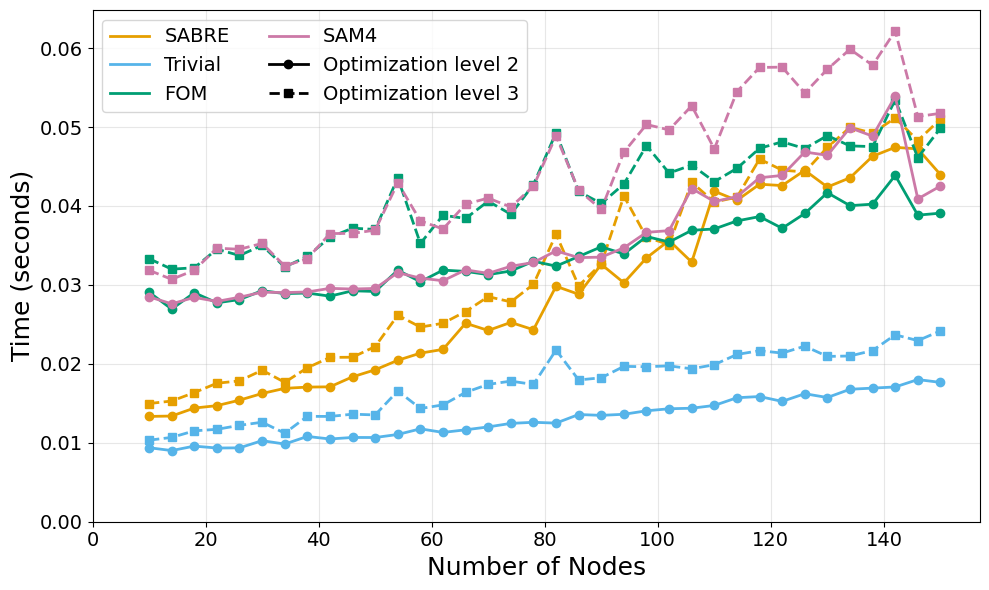

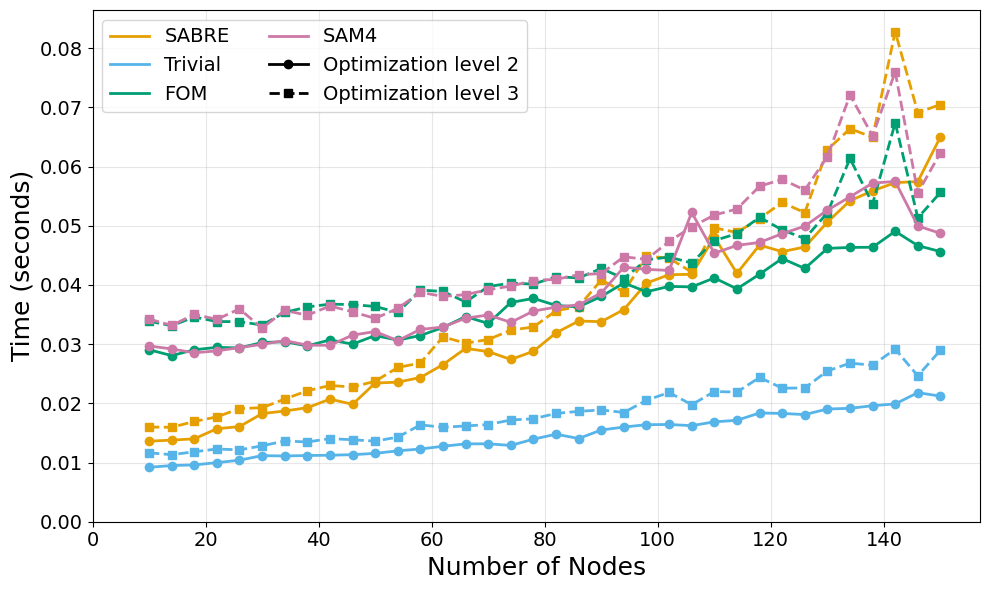

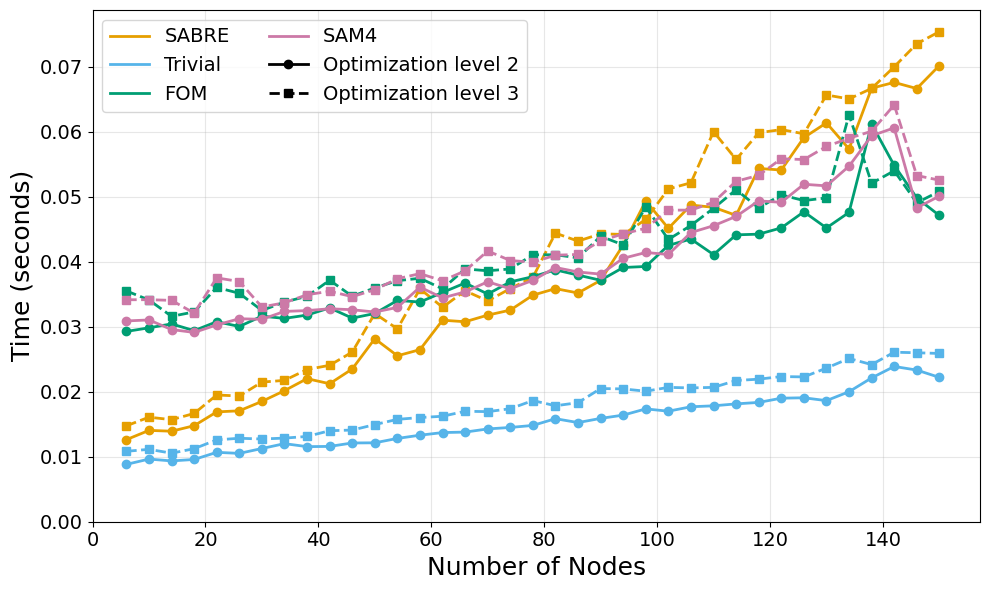

In [10]:

method_colors_opt = {
    'SABRE': '#E69F00',
    'Trivial': '#56B4E9',
    'FOM': '#009E73',
    'SAM2': '#0072B2',
    'SAM3': '#D55E00',
    'SAM4': '#CC79A7',
    'SAM5': '#F0E442',
}
opt_level_styles = {
    2: ('-', 'o'),
    3: ('--', 's'),
}

for case_key, (_, _, node_sizes, graph_label) in opt_level_cases.items():
    fig, ax = plt.subplots(figsize=(10, 6))
    methods = list(
        times_by_opt_level['2'][case_key]['total_compilation_time']['medians']
    )
    for method in methods:
        for optimization_level in OPT_LEVELS_TO_COMPARE:
            linestyle, marker = opt_level_styles[optimization_level]
            values = times_by_opt_level[str(optimization_level)][case_key][
                'total_compilation_time'
            ]['trimmed_means'][method]
            ax.plot(
                node_sizes[::2],
                values[::2],
                color=method_colors_opt.get(method),
                linestyle=linestyle,
                marker=marker,
                linewidth=2,
            )

    method_handles = [
        Line2D([0], [0], color=method_colors_opt.get(method), linewidth=2, label=method)
        for method in methods
    ]
    level_handles = [
        Line2D(
            [0], [0], color='black', linestyle=opt_level_styles[level][0],
            marker=opt_level_styles[level][1], linewidth=2,
            label=f'Optimization level {level}',
        )
        for level in OPT_LEVELS_TO_COMPARE
    ]
    ax.legend(handles=method_handles + level_handles, ncol=2, fontsize=14)
    ax.set_xlabel('Number of Nodes', fontsize=18)
    ax.set_ylabel('Time (seconds)', fontsize=18)
    # ax.set_title(f'{graph_label}: total compilation time')
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


## Trimmed-mean timing plots for the requested graph families

For each graph size and method, the trimmed mean removes one smallest and one largest repetition time, then averages the remaining samples. With fewer than three repetitions it uses the available mean. This section reuses in-memory timing results when they contain trimmed means, otherwise it collects only the requested cases. It saves those results in `comparison_plots_revision_time_trimmed_opt1_2_3.json` so future plot edits can load the samples summary without rerunning timings.


In [16]:
k_list = [4]
average_over = 10
reps = 1
opt_level = 1

# Keep the graph sizes and parameter ranges comparable to comparison_plots_final.ipynb.
nodes_reg = list(range(10, 151, 2))
params_reg = list(range(3, 9))
nodes_ba = list(range(6, 151, 2))
params_ba = list(range(2, 5))

Loaded trimmed timing results from c:\Users\devra\Projects\Qubit Routing\submissions\comparison_plots_revision_time_trimmed_opt1_2_3.json


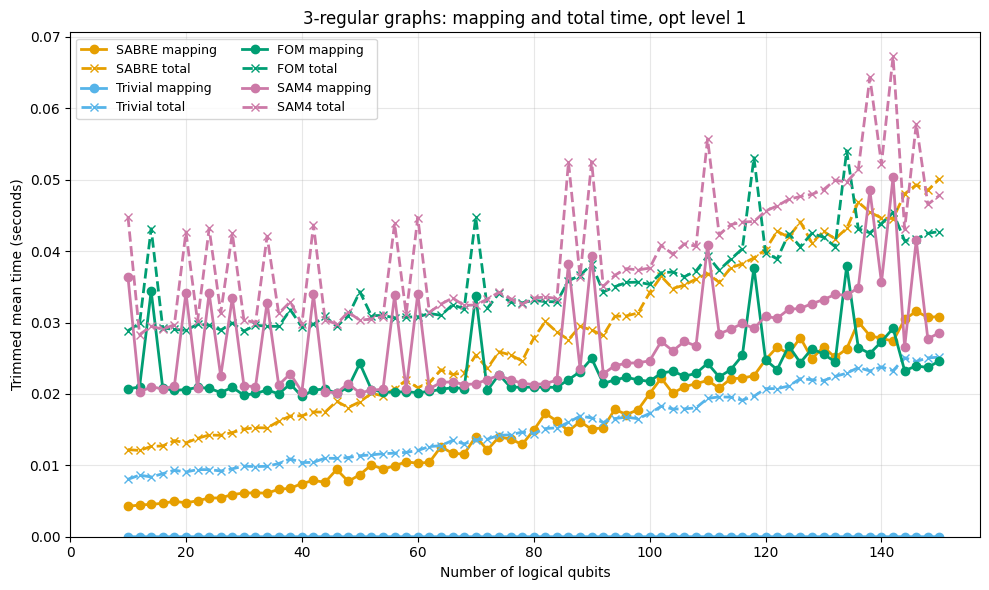

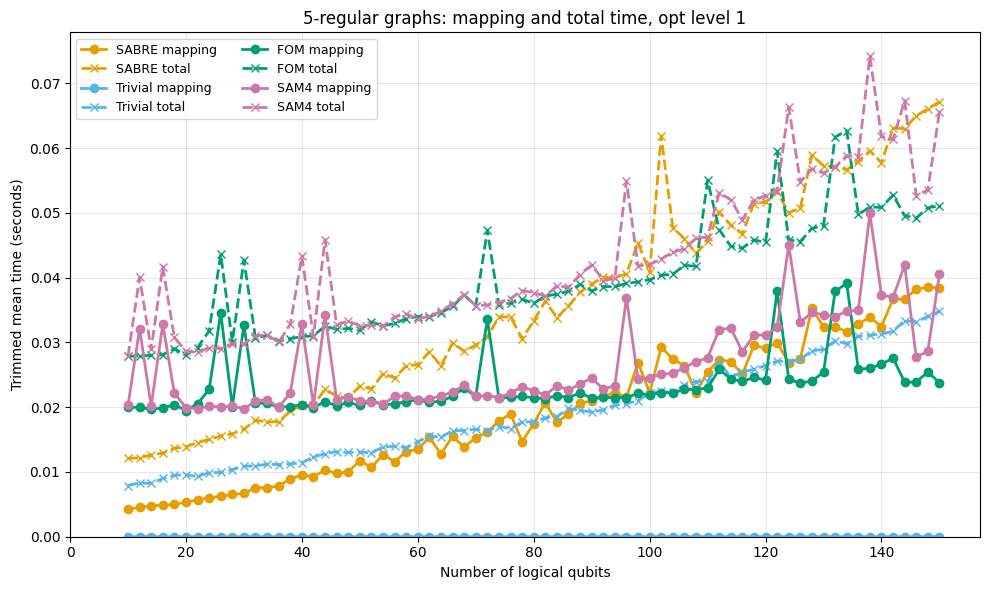

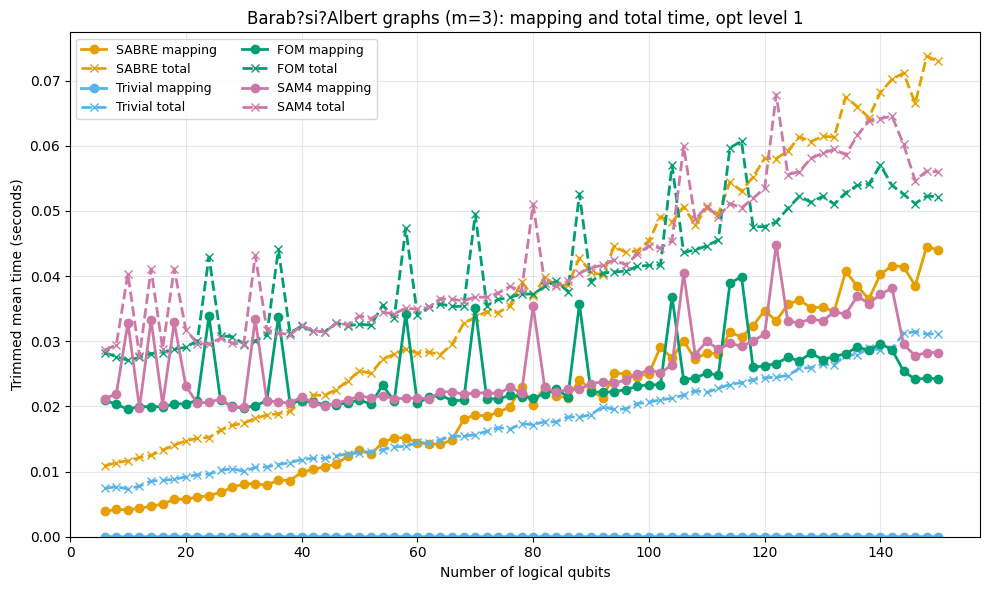

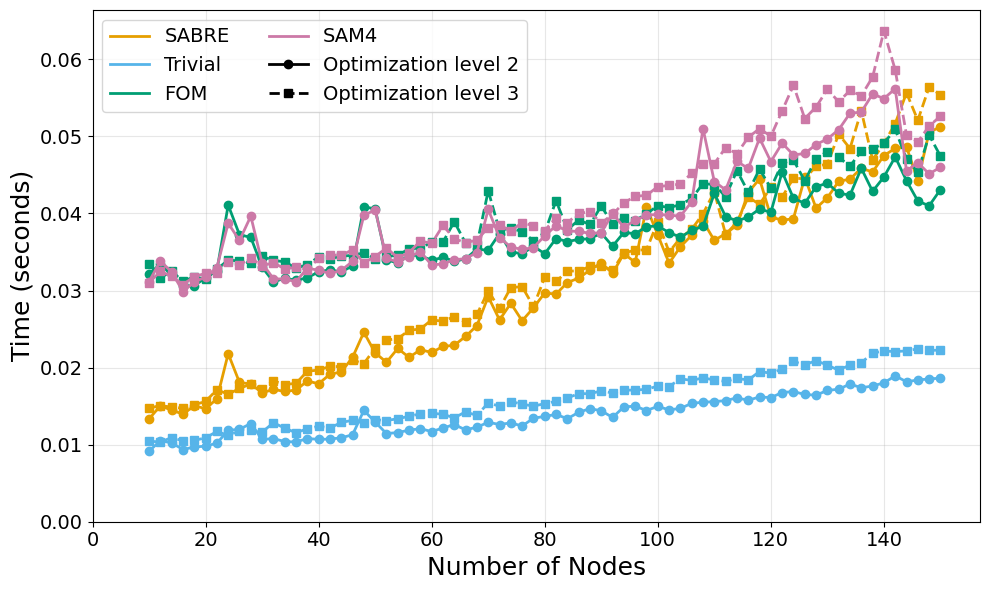

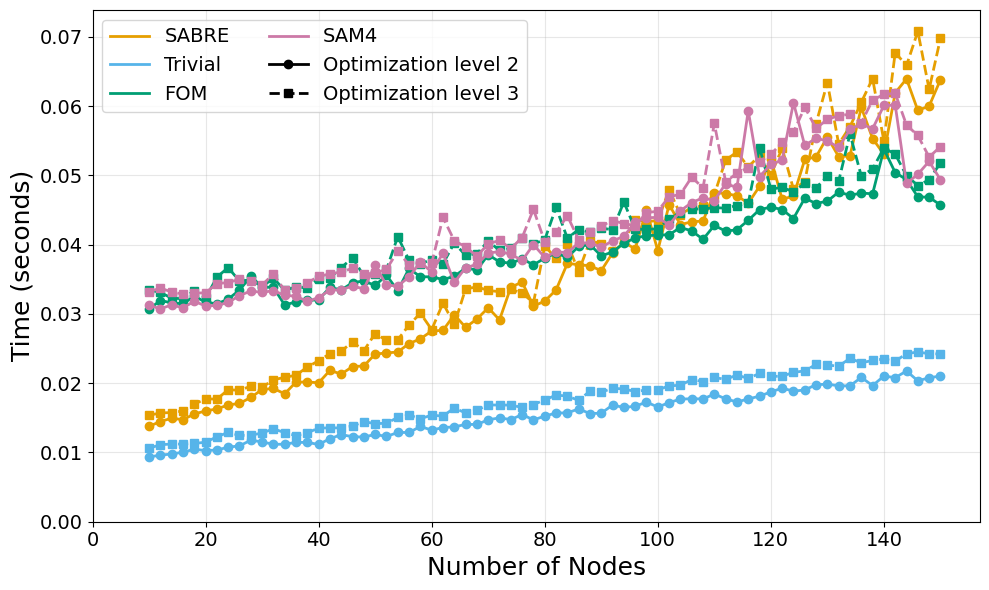

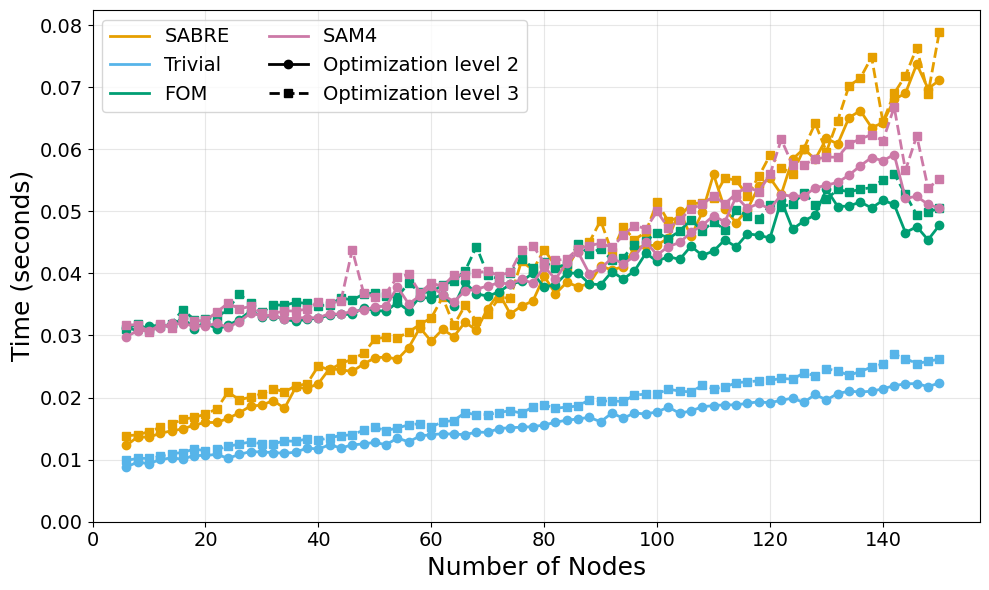

In [22]:
import importlib
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import helper_functions as _helper_functions

# Make sure the current notebook kernel uses the helper version that returns trimmed_means.
importlib.reload(_helper_functions)
return_times_all_methods = _helper_functions.return_times_all_methods

trimmed_case_specs = {
    'reg_d3': ('reg', 3, nodes_reg, '3-regular graphs'),
    'reg_d5': ('reg', 5, nodes_reg, '5-regular graphs'),
    'ba_m3': ('ba', 3, nodes_ba, 'Barab?si?Albert graphs (m=3)'),
}
trimmed_levels = [1, 2, 3]
trimmed_config = {
    'opt_levels': trimmed_levels,
    'average_over': int(average_over),
    'reps': int(reps),
    'k_list': list(k_list),
    'nodes_reg': list(nodes_reg),
    'nodes_ba': list(nodes_ba),
    'noise_aware': True,
    'trim_rule': 'drop-one-lowest-and-one-highest-when-at-least-three-samples',
    'cases': {
        key: {'graph_type': value[0], 'param': value[1]}
        for key, value in trimmed_case_specs.items()
    },
}
_trimmed_cache_dir = Path.cwd()
if not (_trimmed_cache_dir / 'helper_functions.py').is_file() and (_trimmed_cache_dir / 'submissions' / 'helper_functions.py').is_file():
    _trimmed_cache_dir = _trimmed_cache_dir / 'submissions'
TRIMMED_TIMES_FILE = _trimmed_cache_dir / 'comparison_plots_revision_time_trimmed_opt1_2_3.json'
RECOMPUTE_TRIMMED_TIMES = False  # Set to True to regenerate the trimmed timing cache.


def _has_trimmed_stats(result):
    return isinstance(result, dict) and all(
        metric in result and 'trimmed_means' in result[metric]
        for metric in ('mapping_time', 'total_compilation_time')
    )


if TRIMMED_TIMES_FILE.exists() and not RECOMPUTE_TRIMMED_TIMES:
    _trimmed_payload = json.loads(TRIMMED_TIMES_FILE.read_text(encoding='utf-8'))
    if _trimmed_payload.get('configuration') != trimmed_config:
        raise ValueError(
            f'{TRIMMED_TIMES_FILE.name} was created with different settings. '
            'Set RECOMPUTE_TRIMMED_TIMES = True to regenerate it.'
        )
    trimmed_time_results = _trimmed_payload.get('results', {})
    print(f'Loaded trimmed timing results from {TRIMMED_TIMES_FILE}')
else:
    trimmed_time_results = {str(level): {} for level in trimmed_levels}
    print('Collecting or reusing timing samples for trimmed-mean plots.')


def save_trimmed_time_checkpoint():
    payload = {
        'configuration': trimmed_config,
        'results': trimmed_time_results,
    }
    TRIMMED_TIMES_FILE.write_text(
        json.dumps(payload, indent=2, ensure_ascii=False),
        encoding='utf-8',
    )


for level in trimmed_levels:
    level_key = str(level)
    trimmed_time_results.setdefault(level_key, {})
    for case_key, (graph_type, graph_param, node_sizes, graph_label) in trimmed_case_specs.items():
        existing = trimmed_time_results[level_key].get(case_key)
        if _has_trimmed_stats(existing):
            continue

        # Reuse results already collected by the earlier notebook cells when possible.
        candidate = None
        if level == 1:
            earlier_results = globals().get('times_reg' if graph_type == 'reg' else 'times_ba', {})
            candidate = earlier_results.get(graph_param) if isinstance(earlier_results, dict) else None
            if opt_level != 1:
                candidate = None
        else:
            earlier_by_level = globals().get('times_by_opt_level', {})
            candidate = earlier_by_level.get(level_key, {}).get(case_key)
        if _has_trimmed_stats(candidate):
            case_results = candidate
            print(f'Reusing opt {level} trimmed samples for {graph_label}.')
        else:
            print(f'Collecting opt {level} trimmed samples for {graph_label}.')
            case_results = return_times_all_methods(
                backend,
                graph_type=graph_type,
                param=graph_param,
                average_over=average_over,
                node_list=node_sizes,
                k_list=k_list,
                reps=reps,
                opt_level=level,
                noise_aware=True,
            )
        if not _has_trimmed_stats(case_results):
            raise KeyError(
                'Trimmed means are missing from return_times_all_methods. '
                'Check that the updated helper_functions.py was loaded.'
            )
        trimmed_time_results[level_key][case_key] = case_results
        save_trimmed_time_checkpoint()
        if level in (2, 3) and isinstance(globals().get('times_by_opt_level'), dict):
            times_by_opt_level.setdefault(level_key, {})[case_key] = case_results
            if callable(globals().get('save_opt_level_checkpoint')):
                save_opt_level_checkpoint()

trimmed_method_colors = {
    'SABRE': '#E69F00',
    'Trivial': '#56B4E9',
    'FOM': '#009E73',
    'SAM2': '#0072B2',
    'SAM3': '#D55E00',
    'SAM4': '#CC79A7',
    'SAM5': '#F0E442',
}

# Opt level 1: mapping and total time in the same plot.
for case_key, (_, _, node_sizes, graph_label) in trimmed_case_specs.items():
    stats = trimmed_time_results['1'][case_key]
    methods = list(stats['mapping_time']['trimmed_means'])
    fig, ax = plt.subplots(figsize=(10, 6))
    for method in methods:
        color = trimmed_method_colors.get(method)
        ax.plot(
            node_sizes,
            stats['mapping_time']['trimmed_means'][method],
            color=color, linestyle='-', marker='o', linewidth=2,
            label=f'{method} mapping',
        )
        ax.plot(
            node_sizes,
            stats['total_compilation_time']['trimmed_means'][method],
            color=color, linestyle='--', marker='x', linewidth=2,
            label=f'{method} total',
        )
    ax.set_xlabel('Number of logical qubits')
    ax.set_ylabel('Trimmed mean time (seconds)')
    ax.set_title(f'{graph_label}: mapping and total time, opt level 1')
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend(ncol=2, fontsize=9)
    fig.tight_layout()
    plt.show()

# Opt levels 2 and 3: total time in the same plot.
opt_level_styles_trimmed = {2: ('-', 'o'), 3: ('--', 's')}
for case_key, (_, _, node_sizes, graph_label) in trimmed_case_specs.items():
    stats_by_level = {
        level: trimmed_time_results[str(level)][case_key]['total_compilation_time']['trimmed_means']
        for level in (2, 3)
    }
    methods = list(stats_by_level[2])
    fig, ax = plt.subplots(figsize=(10, 6))
    for method in methods:
        for level in (2, 3):
            linestyle, marker = opt_level_styles_trimmed[level]
            ax.plot(
                node_sizes,
                stats_by_level[level][method],
                color=trimmed_method_colors.get(method),
                linestyle=linestyle,
                marker=marker,
                linewidth=2,
            )
    method_handles = [
        Line2D([0], [0], color=trimmed_method_colors.get(method), linewidth=2, label=method)
        for method in methods
    ]
    level_handles = [
        Line2D(
            [0], [0], color='black', linestyle=opt_level_styles_trimmed[level][0],
            marker=opt_level_styles_trimmed[level][1], linewidth=2,
            label=f'Optimization level {level}',
        )
        for level in (2, 3)
    ]
    ax.legend(handles=method_handles + level_handles, ncol=2, fontsize=14)
    ax.set_xlabel('Number of Nodes', fontsize=18)
    ax.set_ylabel('Time (seconds)', fontsize=18)
    # ax.set_title(f'{graph_label}: total time, opt levels 2 and 3')
    ax.tick_params(axis='both', which='major', labelsize=14)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
